# **Fraud Analysis - Cross-Border Remittance Book 2026**

**Author:** Vincent Mbira

**Period Covered:** 1 January - Septemher 2026 (YTD as at 24th September 2026)

**Volume:** 158,020 transactions analyzed | 14,819 customers  | $43.4Mn attempted | $35.4Mn settled

### **Objective:**
Establish what normal looks like in this book, identify fraud patterns from behavioural and network evidence, evaluate how the live rules are performing against both fraud and genuine customers, and recommend changes.

### **Data & Provenance:**
Two files:

    - `remittance_transactions_2026.csv`  —> transaction ledger, 15 fields, one row per payment attempt.
    - `fraud_labels_2026.csv`  —> confirmed bad outcomes (chargebacks, confirmed takeover, mule confirmations, customer scam claims).

**N/B:** *The data is synthetic, constructed to mirror the structure of a live remittance book. Findings demonstrate method, not industry benchmarks.*


### **Methodological Choice:** labels are quarantined
The labels are deliberately **not loaded until section 8**. Sections 2–7 are performed blind, as they would be in a real investigation where fraud is identified before confirmation arrives. The labels are then used to score the findings rather than to generate them.

This matters because the labels have three properties that make them unsuitable as ground truth on their own:

    1. **Delayed** — cases confirm weeks after the payment, so recent weeks look artificially clean. That is label immaturity, not lower fraud.
    2. **Incomplete** — not every bad payment is reported. Absence of a label is weak evidence of legitimacy.
    3. **Structurally biased** — only settled payments can ever be labelled. A blocked payment never moved money and so can never generate a chargeback. Any precision measured against these labels is biased by construction, and the analysis corrects for this rather than ignoring it.

### **Clarification on the `Status` record on the transactions:**
`status` records the system's decision, not the truth. `BLOCKED_RISK` means a rule fired, not that fraud occurred. `COMPLETED` means nothing stopped the payment, not that it was genuine. Rule behaviour is therefore evaluated as a separate question from fraud detection, and block status is never used as a fraud label.

### **Conventions:**
- **Attempted** = all rows. Used for rule behaviour and fraud attempts.
- **Settled** = `status == 'COMPLETED'`. Used for money paid out and all loss figures.
- `FAILED_TECH` and `PENDING_REVIEW` are neither successes nor risk decisions: excluded from loss figures, retained in attempt counts.
- Monthly comparisons use rates per 1,000 transactions, not counts, because the book more than doubled over the period.

### **Notebook structure:**
1. Load & data-quality checks
2. Portfolio overview, baseline & EDA
3. Feature engineering - behavioral, network, & link features)
4. Fraud pattern discovery (unlabelled)
5. Rule performance evaluation
6. Prototype risk score & back-test
7. Self-checks and Validation
8. Labelled evaluation, findings, and recommendations

## **1. Load & Data-quality Checks**


In [1]:
!pip install pandas numpy matplotlib seaborn networkx

In [2]:
# loading the libraries
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

In [3]:
# setting the style of the plots

# setting the display options for pandas and matplotlib
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

# setting the style of the plots
sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [4]:
# loading the dataset

filepath = "D:\\Job Application\\NALA Money Fraud Analyst\\remittance_transactions_2026.csv"
df = pd.read_csv(filepath, parse_dates=['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
print(df.shape)
df.head()

(158140, 15)


,txn_id,timestamp,customer_id,account_age_days,send_country,receive_country,amount_usd,payment_method,card_fingerprint,device_id,ip_country,recipient_id,three_ds,status,blocked_by_rule
0,T1000000,2026-01-01 00:01:00,C008621,1056,FR,IN,887.31,APPLE_PAY,F006054,D011522,FR,R003239,U,COMPLETED,NaN
1,T1000001,2026-01-01 00:34:00,C002823,468,de,IN,173.09,CARD,F000701,D000685,DE,R009419,Y,COMPLETED,NaN
2,T1000002,2026-01-01 00:55:00,C004419,71,GB,GH,63.59,BANK_TRANSFER,NaN,D011305,GB,R020130,NaN,COMPLETED,NaN
3,T1000003,2026-01-01 01:46:00,C003763,100,GB,PK,200.00,CARD,F002891,D006937,GB,R011190,U,COMPLETED,NaN
4,T1000004,2026-01-01 02:24:00,C002836,703,US,BD,200.00,APPLE_PAY,F003516,D011785,US,R002857,Y,COMPLETED,NaN


In [5]:
df.dtypes

txn_id                         str
timestamp           datetime64[us]
customer_id                    str
account_age_days             int64
send_country                   str
receive_country                str
amount_usd                 float64
payment_method                 str
card_fingerprint               str
device_id                      str
ip_country                     str
recipient_id                   str
three_ds                       str
status                         str
blocked_by_rule                str
dtype: object

In [6]:
# checking the data types and missing values
df.dtypes
df.isna().sum()
print('rows:', len(df), '| unique txn_id:', df.txn_id.nunique())
print('fully duplicated rows:', df.duplicated().sum())
df['timestamp'] = pd.to_datetime(df.timestamp, errors='coerce')
print('unparsed timestamps:', df.timestamp.isna().sum())
print('range:', df.timestamp.min(), '->', df.timestamp.max())
for c in ['send_country','receive_country','ip_country','payment_method','three_ds','status','blocked_by_rule']:
    print(f'\n{c} ({df[c].nunique()} distinct):'); print(df[c].value_counts(dropna=False).head(12))
df.amount_usd.describe([.01,.25,.5,.75,.95,.99])
df.account_age_days.describe()

rows: 158140 | unique txn_id: 158020
fully duplicated rows: 120
unparsed timestamps: 0
range: 2026-01-01 00:01:00 -> 2026-09-23 14:05:00

send_country (10 distinct):
send_country
GB    52380
US    46891
DE    22162
FR    21296
IE    14779
gb      224
us      158
de       98
fr       89
ie       63
Name: count, dtype: int64

receive_country (20 distinct):
receive_country
IN     24026
NG     23933
PK     23233
GH     22450
KE     22082
BD     13523
CM     11296
SN     10254
UG      4277
TZ      2592
KE        79
PK        75
Name: count, dtype: int64

ip_country (18 distinct):
ip_country
GB     51969
US     46537
DE     22314
FR     21250
IE     14942
NaN      316
GH       163
NG       154
RU        84
ID        71
IN        63
PK        58
Name: count, dtype: int64

payment_method (3 distinct):
payment_method
CARD             75079
BANK_TRANSFER    45413
APPLE_PAY        37648
Name: count, dtype: int64

three_ds (3 distinct):
three_ds
Y      91485
NaN    45413
U      16448
N       4794


count    158140.000000
mean        564.593360
std         527.588036
min          -1.000000
25%          80.000000
50%         393.000000
75%        1017.000000
max        1761.000000
Name: account_age_days, dtype: float64

**Duplicates:** There are about 120 rows that are duplicated, these will be dropped.

**Fragmented Country codes:** Some of the country codes are in lowcase and others are uppercase thus we will clean them. 

**Missing IP country:** 316 records have missing ip_country entries and this could be signals of potential account takeovers. Wll inestigate them during the analysis. 

In [7]:
# cleaning the data
clean = df.drop_duplicates().copy()
for c in ['send_country','receive_country','ip_country']:
    clean[c] = clean[c].str.strip().str.upper()
clean['ip_country'] = clean['ip_country'].fillna('UNKNOWN')


In [8]:
# reconciliation trail
print(f"raw rows        : {len(df):,}")
print(f"exact duplicates: {len(df)-len(clean):,}")
print(f"clean rows      : {len(clean):,}")
print(f"unique txn_id   : {clean.txn_id.nunique():,}")

raw rows        : 158,140
exact duplicates: 120
clean rows      : 158,020
unique txn_id   : 158,020


In [9]:
# structural null assumptions, tested not assumed
bt = clean.payment_method == 'BANK_TRANSFER'
print('\ncard payments missing fingerprint:', clean.loc[~bt,'card_fingerprint'].isna().sum())
print('bank transfers with a fingerprint:', clean.loc[bt,'card_fingerprint'].notna().sum())
assert (clean.blocked_by_rule.notna() == (clean.status=='BLOCKED_RISK')).all()


card payments missing fingerprint: 0
bank transfers with a fingerprint: 0


In [10]:
print('\nsend:', sorted(clean.send_country.unique()))
print('receive:', sorted(clean.receive_country.unique()))
print('ip:', sorted(clean.ip_country.unique()))


send: ['DE', 'FR', 'GB', 'IE', 'US']
receive: ['BD', 'CM', 'GH', 'IN', 'KE', 'NG', 'PK', 'SN', 'TZ', 'UG']
ip: ['BD', 'BR', 'CM', 'DE', 'FR', 'GB', 'GH', 'ID', 'IE', 'IN', 'KE', 'NG', 'PK', 'RU', 'SN', 'TZ', 'UG', 'UNKNOWN', 'US']


In [11]:
# impossible values
print('\nnegative account_age_days:', (clean.account_age_days < 0).sum())
print('zero or negative amounts  :', (clean.amount_usd <= 0).sum())
display(clean.amount_usd.describe([.01,.25,.5,.75,.95,.99]).round(2))
display(clean.account_age_days.describe().round(1))


negative account_age_days: 40
zero or negative amounts  : 0


count    158020.00
mean        274.93
std         283.97
min           1.01
1%           40.33
25%         132.05
50%         201.97
75%         321.03
95%         685.56
99%        1369.73
max        9000.00
Name: amount_usd, dtype: float64

count    158020.0
mean        564.6
std         527.6
min          -1.0
25%          80.0
50%         393.0
75%        1017.0
max        1761.0
Name: account_age_days, dtype: float64

In [12]:
# account age repair

clean.loc[clean.account_age_days < 0, 'account_age_days'] = np.nan
print('corrupted account ages:', clean.account_age_days.isna().sum())

# reconstruct from the customer's implied signup date
clean['signup'] = clean.timestamp.dt.normalize() - pd.to_timedelta(clean.account_age_days, unit='D')
sign = clean.groupby('customer_id').signup.median()

# consistency check: does each customer's implied signup hold still?
spread = clean.groupby('customer_id').signup.agg(lambda s: (s.max()-s.min()).days if s.notna().any() else np.nan)
print('customers with signup spread > 1 day:', (spread > 1).sum())

fix = clean.account_age_days.isna()
clean.loc[fix, 'account_age_days'] = (
    clean.loc[fix, 'timestamp'].dt.normalize() - clean.loc[fix, 'customer_id'].map(sign)
).dt.days
print('still missing after repair:', clean.account_age_days.isna().sum())
print('new minimum:', clean.account_age_days.min())

corrupted account ages: 40


customers with signup spread > 1 day: 0
still missing after repair: 2
new minimum: 0.0


## 2.**Portfolio Overview**

In [13]:
print(f"transactions : {len(clean):,}")
print(f"customers    : {clean.customer_id.nunique():,}")
print(f"recipients   : {clean.recipient_id.nunique():,}")
print(f"devices      : {clean.device_id.nunique():,}")
print(f"total sent   : ${clean.amount_usd.sum():,.0f}")
settled = clean[clean.status == 'COMPLETED']
print(f"settled value: ${settled.amount_usd.sum():,.0f}")

display(clean.amount_usd.describe([.01,.25,.5,.75,.9,.95,.99]).round(2))

# outcome mix
display(clean.status.value_counts().to_frame('n').assign(pct=lambda x: (100*x.n/len(clean)).round(2)))

# monthly trend: volume, value, and outcome rates
m = clean.groupby(clean.timestamp.dt.to_period('M')).agg(
    txns=('txn_id','size'),
    value=('amount_usd','sum'),
    avg_ticket=('amount_usd','mean'),
    customers=('customer_id','nunique'),
    decline_rate=('status', lambda s: (s=='DECLINED_ISSUER').mean()),
    block_rate=('status', lambda s: (s=='BLOCKED_RISK').mean()))
display(m.round(3))

# corridor mix
corr = clean.groupby(['send_country','receive_country']).agg(
    txns=('txn_id','size'), value=('amount_usd','sum'), median_amt=('amount_usd','median'))
display(corr.sort_values('txns', ascending=False).head(15).round(0))

transactions : 158,020
customers    : 14,819
recipients   : 22,673
devices      : 14,642
total sent   : $43,443,966
settled value: $35,426,160


count    158020.00
mean        274.93
std         283.97
min           1.01
1%           40.33
25%         132.05
50%         201.97
75%         321.03
90%         502.84
95%         685.56
99%        1369.73
max        9000.00
Name: amount_usd, dtype: float64

,n,pct
status,,
COMPLETED,139215,88.10
DECLINED_ISSUER,13315,8.43
BLOCKED_RISK,4568,2.89
FAILED_TECH,622,0.39
PENDING_REVIEW,300,0.19


,txns,value,avg_ticket,customers,decline_rate,block_rate
timestamp,,,,,,
2026-01,10288,2840831.72,276.131,4590,0.085,0.017
2026-02,10157,2804237.53,276.089,4918,0.088,0.011
2026-03,14776,4094832.30,277.127,6106,0.085,0.012
2026-04,14510,3950263.26,272.244,6502,0.086,0.011
2026-05,20236,5579452.17,275.719,7946,0.085,0.030
2026-06,19585,5327808.86,272.035,8273,0.085,0.037
2026-07,22896,6383412.51,278.800,9295,0.083,0.040
2026-08,26389,7252505.10,274.831,10468,0.082,0.037
2026-09,19183,5210622.07,271.627,9402,0.082,0.037


txns      value  median_amt
send_country receive_country                              
GB           NG               10774  2855668.0       200.0
             PK                9767  3099148.0       244.0
US           IN                9690  3374478.0       259.0
GB           GH                8382  2042628.0       189.0
             KE                8177  1898611.0       175.0
US           NG                7243  2010927.0       206.0
             KE                7090  1623712.0       176.0
GB           IN                6394  2119196.0       250.0
US           PK                6157  1937126.0       242.0
             GH                5437  1398893.0       197.0
             BD                4914  1410274.0       216.0
FR           SN                4490  1182460.0       200.0
GB           BD                3997  1111873.0       203.0
FR           CM                3893   964206.0       193.0
DE           IN                3427  1233692.0       264.0

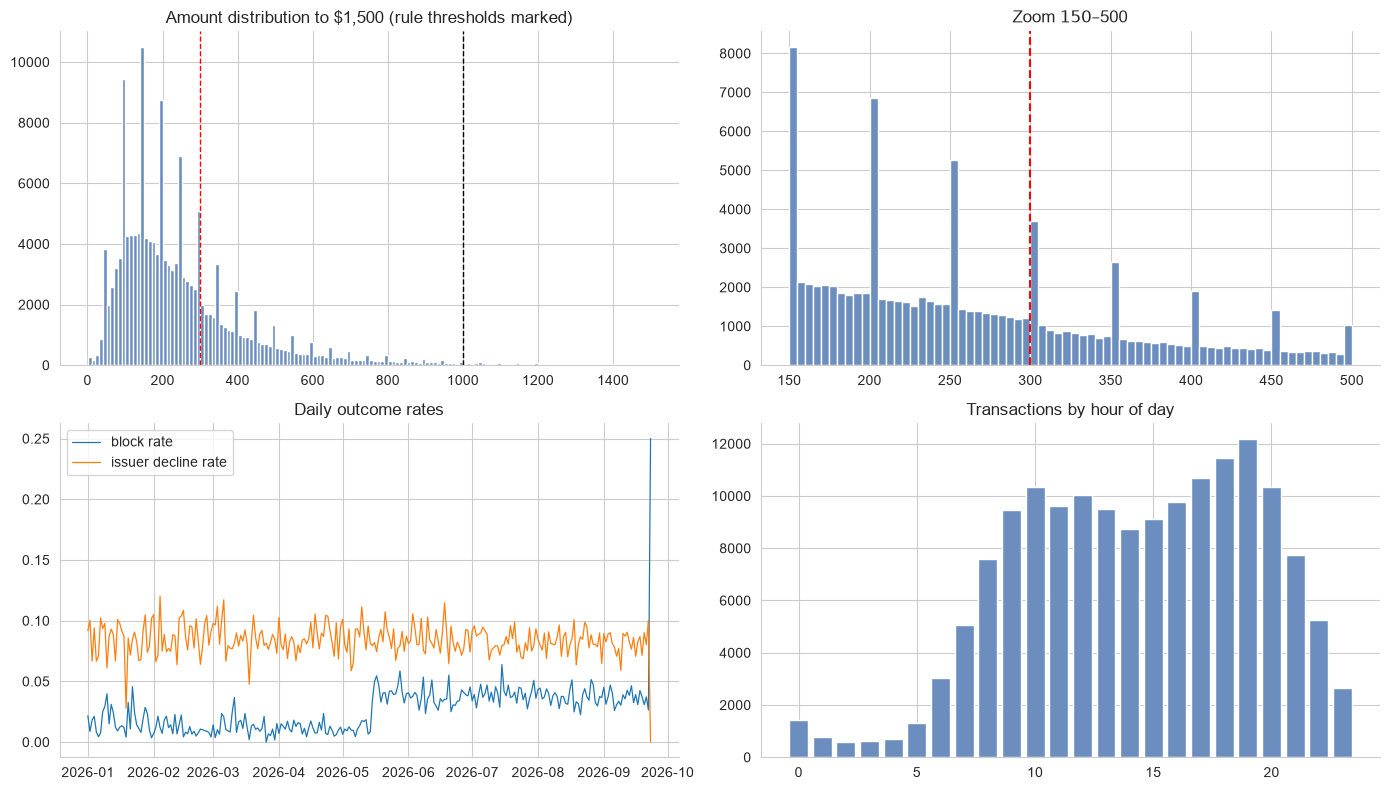

,txns per customer,txns per recipient,txns per device,custs per device,custs per recipient
count,14819.00,22673.00,14642.00,14642.00,22673.00
mean,10.66,6.97,10.79,1.02,1.01
std,9.15,6.82,9.28,0.16,0.25
min,1.00,1.00,1.00,1.00,1.00
50%,8.00,5.00,8.00,1.00,1.00
90%,24.00,15.00,24.00,1.00,1.00
99%,41.00,34.00,42.00,2.00,1.00
max,58.00,55.00,70.00,6.00,8.00


top 1% of customers hold 6.1 % of value


count   mean    std   min    50%    75%    90%     max
send_country receive_country                                                          
GB           NG               10774.0  265.0  250.0  10.0  200.0  310.0  498.0  4278.0
             PK                9767.0  317.0  307.0   2.0  244.0  372.0  582.0  5839.0
US           IN                9690.0  348.0  365.0   1.0  259.0  410.0  643.0  9000.0
GB           GH                8382.0  244.0  249.0   1.0  189.0  294.0  444.0  7412.0
             KE                8177.0  232.0  236.0   2.0  175.0  273.0  430.0  6834.0
US           NG                7243.0  278.0  295.0   4.0  206.0  318.0  500.0  9000.0
             KE                7090.0  229.0  224.0   3.0  176.0  271.0  411.0  4590.0
GB           IN                6394.0  331.0  314.0   1.0  250.0  400.0  611.0  6692.0
US           PK                6157.0  315.0  305.0   1.0  242.0  368.0  575.0  6017.0
             GH                5437.0  257.0  285.0   7.0  197.0  300.0  482.0  8591.0
             BD                4914.0  287.0  286.0   3.0  216.0  327.0  513.0  3736.0
FR           SN                4490.0  263.0  244.0   3.0  200.0  303.0  500.0  2754.0


share of all payments above $300: 0.275
share above $1,000            : 0.02


In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

# (a) amount distribution around the known rule thresholds
sub = clean[clean.amount_usd <= 1500]
ax[0,0].hist(sub.amount_usd, bins=150, color='#6c8ebf')
for t, c in [(300,'red'), (1000,'black')]:
    ax[0,0].axvline(t, color=c, ls='--', lw=1)
ax[0,0].set_title('Amount distribution to $1,500 (rule thresholds marked)')

# (b) zoom: is there a cliff or spike at 300?
z = clean[clean.amount_usd.between(150, 500)]
ax[0,1].hist(z.amount_usd, bins=70, color='#6c8ebf')
ax[0,1].axvline(300, color='red', ls='--')
ax[0,1].set_title('Zoom $150–$500')

# (c) daily block rate — pins the date of the step change
d = clean.groupby(clean.timestamp.dt.date).status.agg(
    block=lambda s: (s=='BLOCKED_RISK').mean(),
    decline=lambda s: (s=='DECLINED_ISSUER').mean())
ax[1,0].plot(pd.to_datetime(d.index), d.block, lw=.9, label='block rate')
ax[1,0].plot(pd.to_datetime(d.index), d.decline, lw=.9, label='issuer decline rate')
ax[1,0].legend(); ax[1,0].set_title('Daily outcome rates')

# (d) hour-of-day baseline
ax[1,1].bar(*np.unique(clean.timestamp.dt.hour, return_counts=True), color='#6c8ebf')
ax[1,1].set_title('Transactions by hour of day')
plt.tight_layout(); plt.show()

# concentration — the tail matters more than the mean
conc = pd.DataFrame({
    'txns per customer' : clean.customer_id.value_counts().describe([.5,.9,.99]),
    'txns per recipient': clean.recipient_id.value_counts().describe([.5,.9,.99]),
    'txns per device'   : clean.device_id.value_counts().describe([.5,.9,.99]),
    'custs per device'  : clean.groupby('device_id').customer_id.nunique().describe([.5,.9,.99]),
    'custs per recipient': clean.groupby('recipient_id').customer_id.nunique().describe([.5,.9,.99]),
}).round(2)
display(conc)

# value concentration
cv = clean.groupby('customer_id').amount_usd.sum().sort_values(ascending=False)
print('top 1% of customers hold', round(100*cv.head(int(len(cv)*.01)).sum()/cv.sum(),1), '% of value')

# corridor amount spread — is a flat threshold defensible?
cs = (clean.groupby(['send_country','receive_country']).amount_usd
        .describe([.5,.75,.9]).round(0).sort_values('count', ascending=False).head(12))
display(cs)
print('\nshare of all payments above $300:', round((clean.amount_usd>300).mean(),3))
print('share above $1,000            :', round((clean.amount_usd>1000).mean(),4))

**What normal looks like (from the tables and charts above):**
- **The book is growing fast.** Volume rose from ~10.3k payments in January to ~26.4k in August, and active customers from ~4.6k to ~10.5k a month. Counts are therefore not comparable month to month; rates are.
- **A typical payment is small and plain.** Median ticket is **$202** (p90 $503, p99 $1,370). 27% of payments are above $300 and only 2% above $1,000, so the two rule thresholds sit at very different points of the distribution. Ticket size is the same across card, wallet and bank transfer.
- **Outcomes are stable apart from blocking.** 88.1% of attempts settle, 8.4% are issuer declines (flat at ~8.5% every month, and the same for new and old accounts), 0.4% technical failures and 0.2% pending review. The only outcome that moves is the **block rate: ~1.2% to ~3.8% from mid-May**, which is a rule change, not a change in customer behaviour (analysed in section 5).
- **Daily rhythm:** activity runs 08:00-21:00 with a peak around 19:00; 00:00-05:59 is under 4% of payments, so night-time activity is a meaningful departure from normal.
- **Customers are repeat senders to a small set of recipients:** median 8 payments per customer; 8,354 customers pay one recipient only, 4,780 pay two and 1,662 pay three. Recipients, cards and devices almost always belong to a single customer. A recipient shared by several unrelated customers is therefore unusual by construction, which is what makes the network analysis in section 4 informative.
- **Corridors:** GB->NG, GB->PK, US->IN, GB->GH and GB->KE lead. The top 1% of customers hold 6% of value, so value is not concentrated in a handful of large senders.

## 3.**Feature Engineering**

### 3.1 Behavioural, velocity and identity features

In [15]:
# Section 3 - feature engineering
# every feature is point-in-time: it uses only information available when the payment was made,
# except the network features, which describe the whole book and are flagged as such
d = clean.sort_values(['timestamp', 'txn_id']).reset_index(drop=True).copy()
d['month'] = d.timestamp.dt.to_period('M')
d['hour']  = d.timestamp.dt.hour
d['settled'] = d.status == 'COMPLETED'
d['decision'] = d.status.isin(['COMPLETED', 'BLOCKED_RISK'])   # payments where a risk decision was actually taken
g = d.groupby('customer_id')

# --- customer history (as at the time of the payment)
d['cust_seq']        = g.cumcount()                                   # 0 = the customer's first payment in the book
d['is_new_recipient'] = ~d.duplicated(['customer_id', 'recipient_id'])
d['is_new_device']   = ~d.duplicated(['customer_id', 'device_id']) & (d.cust_seq > 0)
d['is_new_fp']       = ~d.duplicated(['customer_id', 'card_fingerprint']) & d.card_fingerprint.notna() & (d.cust_seq > 0)
d['hist_mean']       = g.amount_usd.transform(lambda s: s.shift().expanding().mean())
d['amt_ratio']       = d.amount_usd / d.hist_mean                     # NaN on a first payment
d['prior_settled']   = d.groupby('customer_id').settled.cumsum() - d.settled
d['prior_big_settled'] = (d.groupby('customer_id').apply(lambda x: ((x.amount_usd > 1000) & x.settled).cumsum()
                          - ((x.amount_usd > 1000) & x.settled), include_groups=False).reset_index(level=0, drop=True))

# --- session / identity consistency
d['ip_mismatch'] = d.ip_country != d.send_country                      # UNKNOWN counts as a mismatch
d['ip_unknown']  = d.ip_country == 'UNKNOWN'
d['ip_high_risk'] = d.ip_mismatch & ~d.ip_country.isin(['GB', 'US', 'DE', 'FR', 'IE', 'UNKNOWN'])

# --- velocity: rolling windows that exclude the current payment
def rolling_by_customer(col, window, how):
    out = d.set_index('timestamp').groupby('customer_id')[col].rolling(window, closed='left').agg(how)
    return out.reset_index(level=0, drop=True).sort_index()
roll = d[['timestamp', 'customer_id', 'amount_usd', 'txn_id']].copy()
for w, name in [('1h', '1h'), ('24h', '24h'), ('7D', '7d')]:
    r = (roll.set_index('timestamp').groupby('customer_id').amount_usd.rolling(w, closed='left').agg(['count', 'sum'])
             .reset_index().rename(columns={'count': f'n_{name}', 'sum': f'amt_{name}'}))
    d = d.merge(r.drop_duplicates(['customer_id', 'timestamp']), on=['customer_id', 'timestamp'], how='left')
d[[c for c in d.columns if c.startswith(('n_', 'amt_'))]] = d[[c for c in d.columns if c.startswith(('n_', 'amt_'))]].fillna(0)
d['amt_24h_incl'] = d.amt_24h + d.amount_usd

# --- amount shape
d['micro']     = d.amount_usd <= 10
d['near_300']  = d.amount_usd.between(270, 300)
d['near_1000'] = d.amount_usd.between(900, 1000)
d['odd_hour']  = d.hour.between(0, 5)
d['new_acct7']  = d.account_age_days <= 7
d['new_acct30'] = d.account_age_days <= 30

# preview of the engineered columns for a few payments
feature_cols = ['is_new_recipient', 'is_new_device', 'is_new_fp', 'amt_ratio', 'prior_settled', 'ip_mismatch', 'n_1h', 'n_24h', 'amt_24h', 'micro', 'new_acct7', 'odd_hour']
print(f'{len(feature_cols)} of the new columns shown; {d.shape[1] - clean.shape[1]} added in total')
display(d[['txn_id', 'customer_id', 'amount_usd'] + feature_cols].sample(8, random_state=3))
display(d[feature_cols].describe().T[['mean', 'min', 'max']].round(3))

12 of the new columns shown; 28 added in total


,txn_id,customer_id,amount_usd,is_new_recipient,is_new_device,is_new_fp,amt_ratio,prior_settled,ip_mismatch,n_1h,n_24h,amt_24h,micro,new_acct7,odd_hour
9192,T1009192,C005533,243.63,True,False,False,0.696086,1,False,0.0,0.0,0.0,False,False,False
138385,T1138385,C003382,650.00,False,False,False,2.324329,18,False,0.0,0.0,0.0,False,False,False
86629,T1086629,C006538,648.38,True,False,False,0.000000,0,False,0.0,0.0,0.0,False,False,False
123782,T1123782,C004900,300.00,True,False,False,0.000000,0,False,0.0,0.0,0.0,False,True,False
140429,T1140429,C009312,159.37,False,False,False,0.519798,5,False,0.0,0.0,0.0,False,False,False
71575,T1071575,C009408,213.62,False,False,False,1.203425,0,False,0.0,0.0,0.0,False,False,False
114979,T1114979,C008988,320.35,False,False,False,1.181352,19,False,0.0,1.0,184.7,False,False,False
56807,T1056807,C004796,445.60,False,False,False,0.949519,5,False,0.0,0.0,0.0,False,False,False


,mean,min,max
amt_ratio,1.038,0.0,60.183
prior_settled,7.782,0.0,50.000
n_1h,0.011,0.0,5.000
n_24h,0.122,0.0,11.000
amt_24h,40.686,0.0,10248.020


### 3.2 Network and link features

In [16]:
# --- network features: who shares what with whom (whole-book view, used for forensics rather than real-time scoring)
d['recipient_custs'] = d.groupby('recipient_id').customer_id.transform('nunique')
d['device_custs']    = d.groupby('device_id').customer_id.transform('nunique')
d['cust_devices']    = d.groupby('customer_id').device_id.transform('nunique')
d['cust_fps']        = d.groupby('customer_id').card_fingerprint.transform('nunique')
d['cust_recipients'] = d.groupby('customer_id').recipient_id.transform('nunique')

# --- link analysis: connect customers through shared recipients and devices (cards are never shared in this book)
G = nx.Graph()
links = d[['customer_id', 'recipient_id', 'device_id']].drop_duplicates()
G.add_edges_from(zip('c:' + links.customer_id, 'r:' + links.recipient_id))
G.add_edges_from(zip('c:' + links.customer_id, 'd:' + links.device_id))
comp_of = {}
for i, comp in enumerate(nx.connected_components(G)):
    for n in comp:
        if n.startswith('c:'):
            comp_of[n[2:]] = i
d['component'] = d.customer_id.map(comp_of)
d['component_custs'] = d.groupby('component').customer_id.transform('nunique')

print('customers linked to at least one other customer :', d.drop_duplicates('customer_id').component_custs.gt(1).sum())
display(d.drop_duplicates('customer_id').component_custs.value_counts().sort_index().rename('customers').to_frame()
          .assign(components=lambda x: (x.customers / x.index.to_series()).round(0).astype(int)).T)
print('new feature columns:', d.shape[1] - clean.shape[1])

customers linked to at least one other customer : 678


component_custs,1,2,3,4,5,6,7,8
customers,14141,418,21,40,50,72,21,56
components,14141,209,7,10,10,12,3,7


new feature columns: 35


**Feature design.** Each feature answers one question a fraud analyst would ask, and is computed **point-in-time** (only payments earlier than the one being scored contribute), so every feature could be calculated in production at the moment of authorisation.

| Family | Features | Question it answers |
|---|---|---|
| History | `is_new_recipient`, `is_new_device`, `is_new_fp`, `amt_ratio`, `prior_settled`, `prior_big_settled` | Is this payment out of character for this customer? |
| Session | `ip_mismatch`, `ip_high_risk`, `ip_unknown`, `odd_hour` | Is it coming from where this customer normally is? |
| Velocity | `n_1h`, `n_24h`, `n_7d`, `amt_24h`, `amt_7d` | Is activity bursting? |
| Amount shape | `micro`, `near_300`, `near_1000`, `new_acct7/30` | Is it a probe, or shaped around a threshold? |
| Network | `recipient_custs`, `device_custs`, `cust_fps`, `component_custs` | Who else touches the same recipient, device or card? |

The **network features are the one exception to point-in-time**: they describe the whole book so that clusters can be found and studied. Section 6 restates them as-at-payment-time before they are used in a score, and section 7 measures how much detection lag that costs.

**Link analysis result.** Joining customers through shared recipients and devices (cards are never shared) leaves 14,141 customers with no link at all. 418 customers sit in **209 pairs**, which is what households look like (two senders, one shared device or beneficiary). 260 customers sit in **49 clusters of 3-8 customers**. Pairs are treated as benign; clusters of 3+ are the analytical target.

## 4.**Fraud Pattern Deep-dives**

### 4.1 Mule clusters: shared recipients and devices

senders,1,2,3,4,5,6,7,8
recipients,22574,33,11,12,12,15,7,9


customers in link-clusters of 3+: 260 across 49 clusters


,customers,recipients,devices,txns,value,median_age,active_days,card_share
count,49.0,49.0,49.0,49.0,49.0,49.0,49.0,49.0
mean,5.3,1.5,3.8,25.7,11880.0,19.0,17.6,1.0
50%,5.0,1.0,4.0,20.0,10357.0,10.0,10.0,1.0
min,3.0,1.0,1.0,7.0,3883.0,4.0,2.0,0.9
max,8.0,7.0,8.0,70.0,27212.4,183.5,237.0,1.0


payout,GH,KE,NG,TZ,SN,BD
clusters by payout country,19,12,7,6,4,1


,ring customers,other customers
customers,260.00,14559.00
median account age at first sight (d),11.00,36.00
median ticket ($),466.29,200.16
share paid by card/wallet,1.00,0.71
median txns per customer,4.00,8.00


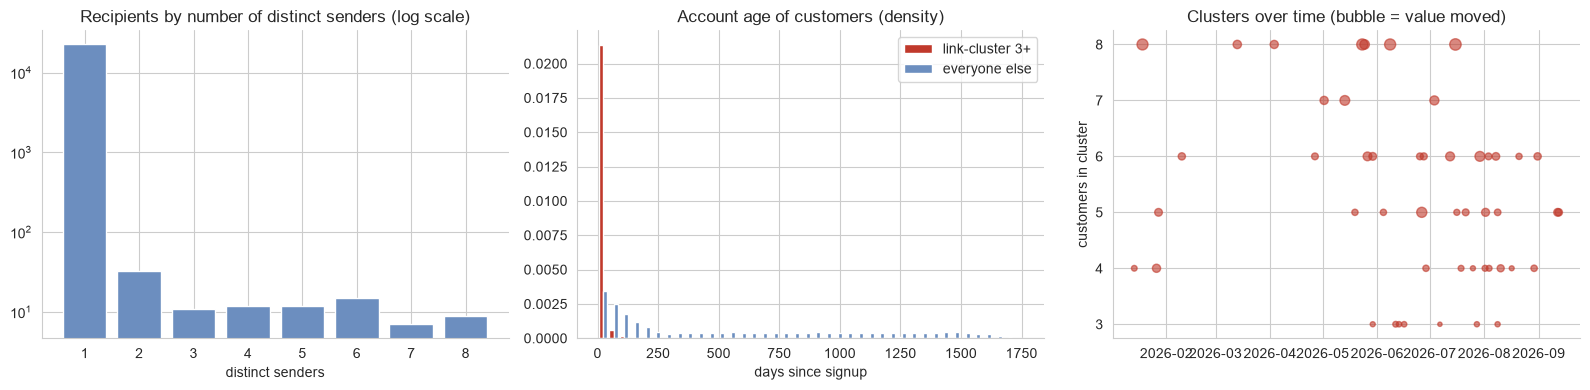

In [17]:
# 4.1 Mule / network rings - recipients that receive money from many unrelated senders
fan = d.groupby('recipient_id').agg(senders=('customer_id', 'nunique'), txns=('txn_id', 'size'),
                                    value=('amount_usd', 'sum'), first=('timestamp', 'min'), last=('timestamp', 'max'))
display(fan.senders.value_counts().sort_index().rename('recipients').to_frame().T)

# a recipient shared by 2 senders is plausibly a household; 3 or more is not
d['ring_member'] = (d.component_custs >= 3) & (d.recipient_custs >= 3)
ring_cust = d[d.component_custs >= 3].drop_duplicates('customer_id')
rest_cust = d[d.component_custs < 3].drop_duplicates('customer_id')
print(f"customers in link-clusters of 3+: {len(ring_cust):,} across {ring_cust.component.nunique()} clusters")

rings = d[d.component_custs >= 3].groupby('component').agg(
    customers=('customer_id', 'nunique'), recipients=('recipient_id', 'nunique'), devices=('device_id', 'nunique'),
    txns=('txn_id', 'size'), value=('amount_usd', 'sum'), median_age=('account_age_days', 'median'),
    first=('timestamp', 'min'), last=('timestamp', 'max'), card_share=('payment_method', lambda s: (s != 'BANK_TRANSFER').mean()),
    payout=('receive_country', lambda s: s.mode().iat[0]))
rings['active_days'] = (rings['last'] - rings['first']).dt.days
display(rings.describe().round(1).loc[['count', 'mean', '50%', 'min', 'max'], ['customers', 'recipients', 'devices', 'txns', 'value', 'median_age', 'active_days', 'card_share']])
display(rings.payout.value_counts().rename('clusters by payout country').to_frame().T)

# how do ring members differ from the other customers?
first_tx = d.drop_duplicates('customer_id')
cmp = pd.DataFrame({
    'ring customers': [len(ring_cust), ring_cust.account_age_days.median(), d[d.component_custs >= 3].amount_usd.median(),
                       (d[d.component_custs >= 3].payment_method != 'BANK_TRANSFER').mean(), d[d.component_custs >= 3].groupby('customer_id').size().median()],
    'other customers': [len(rest_cust), rest_cust.account_age_days.median(), d[d.component_custs < 3].amount_usd.median(),
                        (d[d.component_custs < 3].payment_method != 'BANK_TRANSFER').mean(), d[d.component_custs < 3].groupby('customer_id').size().median()]},
    index=['customers', 'median account age at first sight (d)', 'median ticket ($)', 'share paid by card/wallet', 'median txns per customer']).round(2)
display(cmp)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(fan.senders.value_counts().sort_index().index.astype(str), fan.senders.value_counts().sort_index().values, color='#6c8ebf')
ax[0].set_yscale('log'); ax[0].set_title('Recipients by number of distinct senders (log scale)'); ax[0].set_xlabel('distinct senders')
ax[1].hist([d[d.component_custs >= 3].account_age_days, d[d.component_custs < 3].account_age_days], bins=40, density=True,
           label=['link-cluster 3+', 'everyone else'], color=['#c0392b', '#6c8ebf'])
ax[1].set_title('Account age of customers (density)'); ax[1].legend(); ax[1].set_xlabel('days since signup')
ax[2].scatter(rings['first'], rings.customers, s=rings.value / 400, alpha=.6, color='#c0392b')
ax[2].set_title('Clusters over time (bubble = value moved)'); ax[2].set_ylabel('customers in cluster')
plt.tight_layout(); plt.show()

**Finding 1 - Mule clusters (recipients that collect from many unrelated senders).**
- 22,574 of 22,673 recipients have one sender. **66 recipients have three or more** (up to 8), a step that the household pattern (2 senders) does not explain.
- Those recipients belong to **49 clusters of 3-8 customers**. A typical cluster has 5 customers, 1-2 recipients and ~4 devices: many senders, very few payout points.
- Cluster customers look different from the rest of the book: **median account age 11 days vs 36**, **median ticket $466 vs $200**, **100% card/wallet funded vs 71%**, and ~4 payments per customer vs 8. They are young accounts moving above-average amounts by card to a shared beneficiary.
- They are **short-lived**: a typical cluster is active for ~10 days (mean ~18) and then goes quiet. Payout countries are concentrated in GH (19 clusters), KE (12), NG (7) and TZ (6).
- This is the signature of recruited or synthetic sender accounts feeding a mule beneficiary. It is a **network** fact, not a per-payment fact, which is why per-transaction rules barely see it (section 5.5).

### 4.2 New-account card abuse

customers who funded with 2+ different cards: 70 (0.47% of customers)


,cards,txns,age_at_first,micro_probes,blocked
count,70.0,70.0,70.0,70.0,70.0
mean,3.3,8.8,1.5,2.7,2.8
50%,3.0,9.0,2.0,2.5,2.5
max,5.0,12.0,3.0,6.0,7.0


,timestamp,account_age_days,amount_usd,payment_method,card_fingerprint,three_ds,status,blocked_by_rule
2199,2026-01-07 22:07:00,3.0,5.80,CARD,F006343,Y,DECLINED_ISSUER,NaN
2206,2026-01-07 22:25:00,3.0,8.60,CARD,F004531,U,COMPLETED,NaN
2209,2026-01-07 22:39:00,3.0,10.93,CARD,F001235,U,COMPLETED,NaN
2210,2026-01-07 22:45:00,3.0,5.34,CARD,F010159,U,DECLINED_ISSUER,NaN
2213,2026-01-07 22:56:00,3.0,3.77,CARD,F006343,U,DECLINED_ISSUER,NaN
2221,2026-01-08 02:06:00,4.0,161.98,CARD,F004531,N,COMPLETED,NaN
2226,2026-01-08 05:22:00,4.0,269.73,CARD,F006343,Y,COMPLETED,NaN
2228,2026-01-08 05:56:00,4.0,590.56,CARD,F006343,U,BLOCKED_RISK,RULE_VELOCITY_24H
2241,2026-01-08 07:46:00,4.0,1299.26,CARD,F006343,Y,BLOCKED_RISK,RULE_VELOCITY_24H
2272,2026-01-08 09:46:00,4.0,2287.64,CARD,F004531,Y,BLOCKED_RISK,RULE_VELOCITY_24H


payments of $10 or less: 254 (0.16%) | on accounts <=7 days old: 75.6% | by card: 85.8%


,txns,median_age,card_share,blocked
micro,,,,
False,157766,395.0,0.474,0.029
True,254,2.0,0.858,0.059


,txns,multi_card_share,micro_share,median_amt,three_ds_Y
account_age_days,,,,,
"(-1, 3]",2974,0.162,0.064,213.290,0.538
"(3, 7]",2444,0.012,0.001,229.130,0.560
"(7, 14]",4076,0.000,0.000,232.405,0.563
"(14, 30]",8685,0.000,0.000,222.640,0.576
"(30, 60]",13690,0.000,0.001,204.345,0.578
"(60, 90]",10969,0.000,0.001,202.520,0.567
"(90, 365]",34395,0.000,0.001,200.000,0.570
"(365, 2000]",80785,0.000,0.000,200.000,0.587


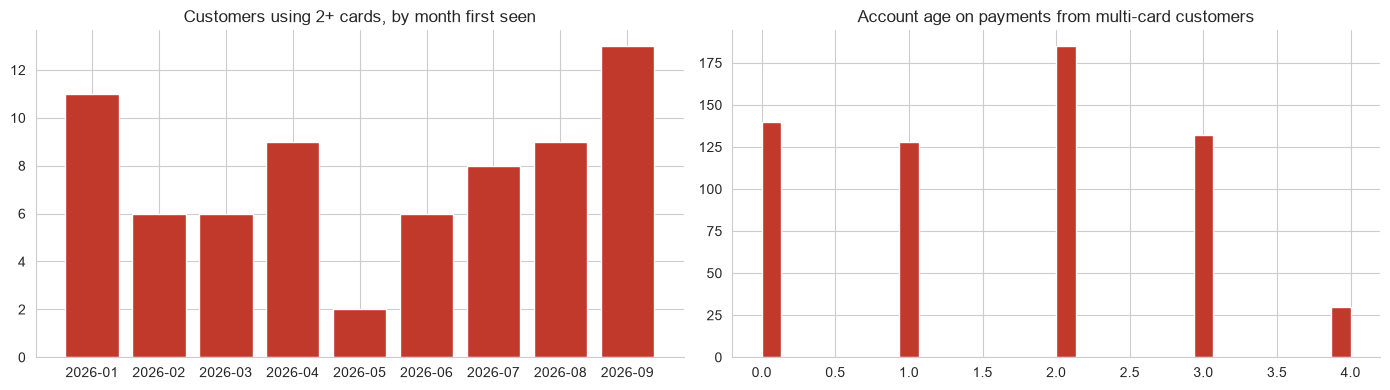

In [18]:
# 4.2 New-account card abuse - many cards, tiny probes, bursts
d['fps_to_date'] = d.groupby('customer_id').is_new_fp.cumsum() + d.card_fingerprint.notna().groupby(d.customer_id).cummax().astype(int)
d['multi_card'] = d.fps_to_date >= 2
mc = d[d.cust_fps >= 2].drop_duplicates('customer_id')
print(f"customers who funded with 2+ different cards: {len(mc):,} ({len(mc)/d.customer_id.nunique():.2%} of customers)")
display(d[d.cust_fps >= 2].groupby('customer_id').agg(cards=('cust_fps', 'first'), txns=('txn_id', 'size'), age_at_first=('account_age_days', 'min'),
        micro_probes=('micro', 'sum'), blocked=('status', lambda s: (s == 'BLOCKED_RISK').sum())).describe().round(1).loc[['count', 'mean', '50%', 'max']])

# anatomy of one account: probes first, then the big payment
ex = d[(d.cust_fps >= 3) & d.micro].customer_id.iloc[0]
display(d[d.customer_id == ex][['timestamp', 'account_age_days', 'amount_usd', 'payment_method', 'card_fingerprint', 'three_ds', 'status', 'blocked_by_rule']].head(10))

# micro payments: who sends them?
mi = d[d.micro]
print(f"payments of $10 or less: {len(mi):,} ({len(mi)/len(d):.2%}) | on accounts <=7 days old: {mi.new_acct7.mean():.1%} | by card: {(mi.payment_method=='CARD').mean():.1%}")
display(d.groupby('micro').agg(txns=('txn_id', 'size'), median_age=('account_age_days', 'median'), card_share=('payment_method', lambda s: (s == 'CARD').mean()),
                               blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean())).round(3))

# account-age hazard: how risky-looking behaviour is concentrated in the first days
age = d.groupby(pd.cut(d.account_age_days, [-1, 3, 7, 14, 30, 60, 90, 365, 2000])).agg(
    txns=('txn_id', 'size'), multi_card_share=('multi_card', 'mean'), micro_share=('micro', 'mean'), median_amt=('amount_usd', 'median'),
    three_ds_Y=('three_ds', lambda s: (s == 'Y').mean()))
display(age.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mm = d[d.cust_fps >= 2].drop_duplicates('customer_id').groupby('month').size()
ax[0].bar(mm.index.astype(str), mm.values, color='#c0392b'); ax[0].set_title('Customers using 2+ cards, by month first seen')
ax[1].hist(d[d.cust_fps >= 2].account_age_days, bins=30, color='#c0392b'); ax[1].set_title('Account age on payments from multi-card customers')
plt.tight_layout(); plt.show()

**Finding 2 - New-account card abuse (card testing and multi-card use).**
- **70 customers (0.47%) fund payments with 2-5 different cards.** Every one is on an account **at most 3 days old**; on average they send ~2.7 micro-payments and have ~2.8 payments blocked.
- The anatomy above is classic card testing: a handful of $3-$11 payments on different cards to find which ones work, then an escalation (162 -> 270 -> 590 -> 1,299 -> 2,288) on the cards that passed.
- **Micro-payments (<= $10) are almost exclusively this behaviour:** 254 payments, 76% on accounts under a week old, 86% by card, median account age 2 days.
- In the first three days of an account, 16% of payments come from multi-card customers; after day 7 it is essentially zero. The age at which the behaviour stops is itself informative: **this risk concentrates in the first week**.

### 4.3 Account takeover and 4.4 scam candidates

In [19]:
# 4.3 Account takeover - an established customer paying from somewhere they have never paid from
tenured = d.account_age_days > 90
print(f"IP country differs from send country: {d.ip_mismatch.mean():.2%} of payments | on tenured accounts: {d[tenured].ip_mismatch.mean():.2%}")
display(d[d.ip_mismatch].ip_country.value_counts().head(15).rename('payments').to_frame().T)
display(d.groupby(d.timestamp.dt.to_period('M')).ip_mismatch.mean().round(4).to_frame('mismatch rate').T)

# a mismatch on its own is mostly noise (travel, VPN). Does it travel with other changes in behaviour?
mm = d[d.ip_mismatch & tenured]
feat = pd.DataFrame({
    'all tenured payments': [d[tenured].is_new_device.mean(), d[tenured].is_new_recipient.mean(), (d[tenured].amt_ratio > 3).mean(),
                             d[tenured].odd_hour.mean(), d[tenured].ip_high_risk.mean()],
    'tenured + IP mismatch': [mm.is_new_device.mean(), mm.is_new_recipient.mean(), (mm.amt_ratio > 3).mean(),
                              mm.odd_hour.mean(), mm.ip_high_risk.mean()]},
    index=['new device', 'new recipient', 'amount > 3x own average', 'sent 00:00-05:59', 'IP outside the five send markets']).round(3)
display(feat)

# the IP-mismatch population, split by what else changed
mm = mm.assign(extra_signals=mm.is_new_device.astype(int) + mm.is_new_recipient.astype(int) + (mm.amt_ratio > 3).astype(int) + mm.odd_hour.astype(int))
display(mm.groupby('extra_signals').agg(txns=('txn_id', 'size'), customers=('customer_id', 'nunique'), median_amt=('amount_usd', 'median'),
        blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean())).round(3))

# customers with repeated mismatches inside a short window look like a compromised account, not a traveller
mm = mm.sort_values(['customer_id', 'timestamp'])
mm['gap_h'] = mm.groupby('customer_id').timestamp.diff().dt.total_seconds() / 3600
print('mismatching customers:', mm.customer_id.nunique(), '| with 2+ mismatches within 72h:', mm[mm.gap_h < 72].customer_id.nunique())
display(d[d.customer_id == mm[mm.gap_h < 72].customer_id.iloc[0]][['timestamp', 'amount_usd', 'send_country', 'ip_country', 'device_id', 'recipient_id', 'payment_method', 'status']].tail(8))

# 4.4 Authorised-push-payment (scam) candidates - the customer is genuine, the payment is out of character
bt = d[(d.payment_method == 'BANK_TRANSFER') & tenured & (d.cust_seq >= 3)]
bt = bt.assign(big=bt.amount_usd > 800)
display(bt.groupby('big').agg(txns=('txn_id', 'size'), median_ratio=('amt_ratio', 'median'), new_recipient=('is_new_recipient', 'mean'),
        blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean()), settled=('settled', 'mean')).round(3))
print('tenured bank-transfer payments above $800 that settled:', int((bt.big & bt.settled).sum()), 'worth $', round(bt[bt.big & bt.settled].amount_usd.sum()))

IP country differs from send country: 1.83% of payments | on tenured accounts: 1.99%


ip_country,IE,DE,FR,UNKNOWN,US,GB,GH,NG,RU,ID,IN,PK,BR,BD,KE
payments,422,383,359,316,303,302,163,154,84,70,63,58,48,42,40


timestamp,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
mismatch rate,0.0194,0.0188,0.0188,0.0186,0.0187,0.0186,0.0194,0.0151,0.0194


,all tenured payments,tenured + IP mismatch
new device,0.001,0.031
new recipient,0.091,0.117
amount > 3x own average,0.033,0.089
sent 00:00-05:59,0.032,0.147
IP outside the five send markets,0.006,0.308


,txns,customers,median_amt,blocked
extra_signals,,,,
0,1714,637,202.475,0.008
1,387,276,300.070,0.248
2,118,84,1272.375,0.729
3,24,24,775.800,0.583
4,46,46,772.935,0.609


mismatching customers: 738 | with 2+ mismatches within 72h: 184


,timestamp,amount_usd,send_country,ip_country,device_id,recipient_id,payment_method,status
62500,2026-05-23 03:44:00,649.46,GB,NG,D003535,R015126,BANK_TRANSFER,BLOCKED_RISK
62501,2026-05-23 04:01:00,973.06,GB,NG,D003535,R015126,BANK_TRANSFER,BLOCKED_RISK
62504,2026-05-23 04:56:00,1245.47,GB,NG,D003535,R015126,BANK_TRANSFER,BLOCKED_RISK
62513,2026-05-23 05:39:00,254.81,GB,NG,D003535,R015126,BANK_TRANSFER,COMPLETED
62515,2026-05-23 06:06:00,1599.22,GB,NG,D003535,R015126,BANK_TRANSFER,COMPLETED
62563,2026-05-23 08:14:00,241.93,GB,NG,D003535,R015126,BANK_TRANSFER,COMPLETED
62598,2026-05-23 09:13:00,263.09,GB,NG,D003535,R015126,BANK_TRANSFER,COMPLETED
62694,2026-05-23 11:05:00,271.08,GB,NG,D003535,R015126,BANK_TRANSFER,COMPLETED


,txns,median_ratio,new_recipient,blocked,settled
big,,,,,
False,26751,0.825,0.017,0.002,0.922
True,961,3.483,0.073,0.176,0.764


tenured bank-transfer payments above $800 that settled: 734 worth $ 910944


**Finding 3 - Account takeover (a long-standing customer acting from somewhere new).**
- An IP country that differs from the send country happens on **1.8% of payments** and the rate is flat every month. A flat rate means it is mostly background (travel, VPNs, cross-border workers), so **a mismatch on its own is not a fraud signal**. Most mismatches are neighbouring markets (IE, DE, FR, US, GB).
- What separates takeover from noise is **combination**. For tenured customers with an IP mismatch, 31% come from countries outside the five send markets (0.6% of all tenured payments), 15% are sent between midnight and 06:00 (3% for all tenured), 9% are more than 3x the customer's own average (3%), and a new device is ~30x more likely.
- Counting the extra signals (new device, new recipient, amount >3x average, night-time) gives a clean gradient: with **no extra signal** the median ticket is $202 and 0.8% are blocked; with **two or more** the median ticket is $775-$1,272 and 58-73% are blocked. The rules are already reacting to the combination, but only through the amount.
- 184 of 738 mismatching customers have **two or more mismatches within 72 hours**: an attacker working an account in a burst (the example above shows the first three attempts blocked and the following five settling).

**Finding 4 - Scam candidates (genuine customer, out-of-character payment).** Among tenured customers' bank transfers, the 961 payments above $800 have a median amount **3.5x the sender's own average** and 76% settle (734 payments, **$911k** settled). Unlike the first three findings this is a *candidate list* rather than a clean cluster: the customer is genuine, the device and IP are normal, and nothing in the identity data distinguishes it. Section 8 tests whether it is a useful signal.

### Summary of blind findings (to be scored in section 8)

| # | Pattern | Evidence used | Why it escapes simple rules |
|---|---|---|---|
| 1 | Mule clusters | Recipient or device shared by 3+ unrelated senders, young accounts, card-funded, short-lived | Each payment is ordinary in size and each sender is new; the signal only exists across customers |
| 2 | Card testing / multi-card new accounts | 2+ cards in the first 3 days, micro-probes then escalation | Early probes are tiny; the rule aimed at it only starts on 11 Jul |
| 3 | Takeover | Tenured account, IP outside the five markets, new device, night-time, amount spike | A foreign IP alone is common and benign |
| 4 | Scam candidates | Tenured bank transfer, large relative to own history | Customer, device and IP all look genuine |

## 5.**Rule Performance Evaluation**

### 5.1 Rule inventory

,blocks,value,median_amt,customers,first_fire,last_fire,share_of_blocks,blocks_per_1000_txns
blocked_by_rule,,,,,,,,
RULE_AMT_1000,1186,1820210.0,1367.0,958,2026-01-01 08:03:00,2026-09-22 12:58:00,0.260,7.51
RULE_CARD_TESTING,69,45127.0,279.0,25,2026-07-11 17:22:00,2026-09-21 07:25:00,0.015,0.44
RULE_NEW_RECIPIENT_300,3092,1850052.0,452.0,2272,2026-05-15 00:06:00,2026-09-23 09:14:00,0.677,19.57
RULE_VELOCITY_24H,221,708490.0,3511.0,166,2026-01-01 11:04:00,2026-09-19 16:04:00,0.048,1.40


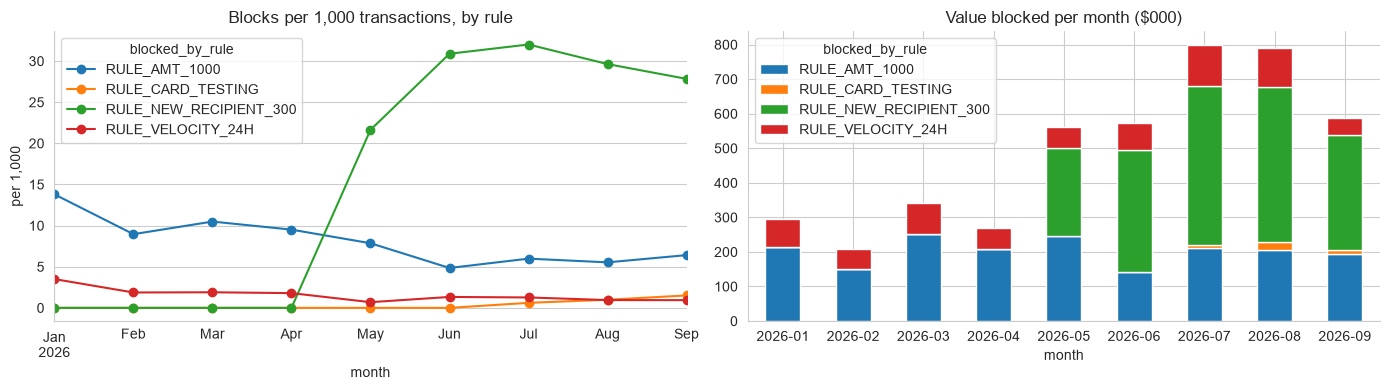

blocked value as % of attempted value, by month:


month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
%,0.104,0.075,0.083,0.068,0.1,0.108,0.125,0.109,0.113


In [20]:
# 5.1 Rule inventory
d['pair'] = d.customer_id + '|' + d.recipient_id
d['recipient_proven'] = (d.groupby('pair').settled.cumsum() - d.settled) > 0      # an earlier payment to this recipient completed
risk = d[d.decision]                                                               # settled or blocked: the payments a rule actually ruled on
blocked = d[d.status == 'BLOCKED_RISK']
inv = blocked.groupby('blocked_by_rule').agg(blocks=('txn_id', 'size'), value=('amount_usd', 'sum'), median_amt=('amount_usd', 'median'),
        customers=('customer_id', 'nunique'), first_fire=('timestamp', 'min'), last_fire=('timestamp', 'max'))
inv['share_of_blocks'] = inv.blocks / inv.blocks.sum()
inv['blocks_per_1000_txns'] = 1000 * inv.blocks / len(d)
display(inv.round({'value': 0, 'median_amt': 0, 'share_of_blocks': 3, 'blocks_per_1000_txns': 2}))

pm = pd.crosstab(d.month, d.blocked_by_rule.fillna('(none)'))
pm_rate = pm.div(d.groupby('month').size(), axis=0) * 1000
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pm_rate.drop(columns='(none)').plot(ax=ax[0], marker='o'); ax[0].set_title('Blocks per 1,000 transactions, by rule'); ax[0].set_ylabel('per 1,000')
(blocked.groupby(['month', 'blocked_by_rule']).amount_usd.sum().unstack().fillna(0) / 1e3).plot.bar(stacked=True, ax=ax[1])
ax[1].set_title('Value blocked per month ($000)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print('blocked value as % of attempted value, by month:'); display((blocked.groupby('month').amount_usd.sum() / d.groupby('month').amount_usd.sum()).round(3).to_frame('%').T)

**Reading the inventory.**
- **Two rules produce 94% of all blocks:** `RULE_NEW_RECIPIENT_300` (3,092 blocks, 67.7%, $1.85M held) and `RULE_AMT_1000` (1,186, 26.0%, $1.82M). `RULE_VELOCITY_24H` (221 blocks, $0.71M) and `RULE_CARD_TESTING` (69 blocks, $45k) are small by volume.
- **The book changed on two dates.** `RULE_NEW_RECIPIENT_300` first fires on **15 May** and `RULE_CARD_TESTING` on **11 Jul**; the other two are live from 1 Jan. The overall block rate moves from **12.5 to 38.2 per 1,000 payments** after 15 May and the value held rises from 6.8-10.4% of attempted value in January-April to 10.0-12.5% from May.
- Because the book more than doubled over the same period, only per-1,000 rates show this correctly.

### 5.2 Inferring the logic of each rule

In [21]:
# 5.2 Inferring the logic of each rule from behaviour
# --- RULE_AMT_1000: which payments above $1,000 get through?
big = d[(d.amount_usd > 1000) & d.decision]
big = big.assign(seg=np.select(
    [big.account_age_days <= 90, big.three_ds.isin(['N', 'U']), big.prior_big_settled == 0],
    ['account <= 90 days', '3DS not authenticated (N/U)', 'tenured, 3DS ok/bank, first large payment'],
    default='tenured, 3DS ok/bank, has settled >$1k before'))
t = big.groupby('seg').agg(payments=('txn_id', 'size'), blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean()),
                           by_amt_rule=('blocked_by_rule', lambda s: (s == 'RULE_AMT_1000').mean()), value=('amount_usd', 'sum'))
display(t.round(3))
print('payments over $1,000 that settled with no rule firing:', int(((d.amount_usd > 1000) & d.settled).sum()), '| value $', round(d[(d.amount_usd > 1000) & d.settled].amount_usd.sum()))

# --- RULE_NEW_RECIPIENT_300: launched on a date, with an allow-list
launch = d[d.blocked_by_rule == 'RULE_NEW_RECIPIENT_300'].timestamp.min().normalize()
print('RULE_NEW_RECIPIENT_300 first fires on', launch.date())
nr = d[(d.timestamp >= launch) & (d.amount_usd > 300) & ~d.recipient_proven & d.decision]
print(f"post-launch payments over $300 to a recipient with no completed history: {len(nr):,} | blocked by this rule: {(nr.blocked_by_rule=='RULE_NEW_RECIPIENT_300').mean():.1%}")
cust_pass = nr.groupby('customer_id').agg(n=('txn_id', 'size'), blk=('blocked_by_rule', lambda s: (s == 'RULE_NEW_RECIPIENT_300').mean()))
display(pd.cut(cust_pass[cust_pass.n >= 3].blk, [-.01, 0, .5, .99, 1]).value_counts().sort_index().rename('customers with 3+ qualifying payments').to_frame().T)
print(f"payments that slipped through: {int((nr.blocked_by_rule.isna()).sum())} across {nr[nr.blocked_by_rule.isna()].customer_id.nunique()} customers - spread thinly, not concentrated on a few accounts")

# --- RULE_VELOCITY_24H: count and value in the trailing 24h
vel = d[d.decision]
display(vel.groupby(pd.cut(vel.n_24h, [-1, 0, 2, 4, 6, 7, 20])).apply(lambda x: pd.Series({'payments': len(x), 'velocity_block_rate': (x.blocked_by_rule == 'RULE_VELOCITY_24H').mean()})).round(3).T)
display(vel.groupby(pd.cut(vel.amt_24h_incl, [0, 1000, 2000, 3000, 3500, 4000, 5000, 10000, 50000])).apply(lambda x: pd.Series({'payments': len(x), 'velocity_block_rate': (x.blocked_by_rule == 'RULE_VELOCITY_24H').mean()})).round(3).T)
v = d[d.blocked_by_rule == 'RULE_VELOCITY_24H']
print(f"velocity blocks with no prior payment in 24h (i.e. a single large payment): {(v.n_24h==0).mean():.0%} | with 7+ prior payments: {(v.n_24h>=7).mean():.0%}")

# --- RULE_CARD_TESTING: launched later and narrowly
ct = d[d.blocked_by_rule == 'RULE_CARD_TESTING']
print(f"RULE_CARD_TESTING first fires {ct.timestamp.min().date()} | {len(ct)} blocks | median account age {ct.account_age_days.median():.0f}d | card only: {(ct.payment_method=='CARD').all()}")
pre_ct = d[(d.timestamp < ct.timestamp.min()) & d.multi_card & d.decision]
print(f"multi-card payments before the rule existed: {len(pre_ct):,} | settled: {pre_ct.settled.mean():.0%}  ->  after launch: {d[(d.timestamp>=ct.timestamp.min()) & d.multi_card & d.decision].settled.mean():.0%}")

,payments,blocked,by_amt_rule,value
seg,,,,
3DS not authenticated (N/U),404,1.000,0.777,679503.83
account <= 90 days,838,1.000,0.696,1397808.41
"tenured, 3DS ok/bank, first large payment",1425,0.305,0.199,2350676.92
"tenured, 3DS ok/bank, has settled >$1k before",371,0.105,0.013,613878.44


payments over $1,000 that settled with no rule firing: 1323 | value $ 1992780
RULE_NEW_RECIPIENT_300 first fires on 2026-05-15
post-launch payments over $300 to a recipient with no completed history: 3,433 | blocked by this rule: 90.1%


blk,"(-0.01, 0.0]","(0.0, 0.5]","(0.5, 0.99]","(0.99, 1.0]"
customers with 3+ qualifying payments,3,1,26,160


payments that slipped through: 306 across 293 customers - spread thinly, not concentrated on a few accounts


n_24h,"(-1, 0]","(0, 2]","(2, 4]","(4, 6]","(6, 7]","(7, 20]"
payments,129547.000,13672.000,278.000,151.000,65.000,70.000
velocity_block_rate,0.001,0.001,0.072,0.013,0.554,0.686


amt_24h_incl,"(0, 1000]","(1000, 2000]","(2000, 3000]","(3000, 3500]","(3500, 4000]","(4000, 5000]","(5000, 10000]","(10000, 50000]"
payments,139093.0,3599.000,609.000,137.000,103.000,78.000,155.000,9.000
velocity_block_rate,0.0,0.005,0.025,0.044,0.563,0.551,0.432,0.444


velocity blocks with no prior payment in 24h (i.e. a single large payment): 43% | with 7+ prior payments: 38%
RULE_CARD_TESTING first fires 2026-07-11 | 69 blocks | median account age 2d | card only: True
multi-card payments before the rule existed: 229 | settled: 60%  ->  after launch: 37%


**Inferred logic of each rule (thresholds and exemptions are not documented, so they are read from behaviour).**

- **`RULE_AMT_1000` is not a flat $1,000 cap; it is tiered by customer risk.** Every payment above $1,000 from an account **90 days old or younger**, or with **3DS not authenticated (N/U)**, ends up blocked (by this rule or, when another rule takes priority, by that one). For tenured customers with 3DS or bank transfer, only **30.5%** of a first large payment is blocked and only **10.5%** once the customer has already settled a payment above $1,000 (1.3% by this rule). 1,323 payments above $1,000 settled with no rule firing, worth **$1.99M**.
- **`RULE_NEW_RECIPIENT_300` applies to ~90% of qualifying payments and is not tied to tenure, payment method, 3DS, corridor or time of day.** Of 3,433 post-launch payments over $300 to a recipient the customer has never completed a payment to, 90.1% are blocked. The ~10% that pass are spread thinly over ~290 customers rather than concentrated on a few allow-listed accounts, which points to an unreliable trigger (or a sampling holdout) rather than a deliberate exemption. This is worth confirming with the rule owner.
- **`RULE_VELOCITY_24H` fires on a count or on a value.** Block probability jumps from <8% to **55-69%** at 7 or more prior payments in 24h, and from <5% to **~55%** once the trailing 24h value including the current payment passes ~$3,500. 43% of its blocks are a single large payment with no prior 24h activity, 38% follow 7 or more payments. It is only a probabilistic filter at those points (never 100%).
- **`RULE_CARD_TESTING` is narrow:** card only, median account age 2 days. Before it existed, **229 multi-card payments** were processed and 60% settled; after launch only 37% settle.

### 5.3 Customer friction and 5.4 threshold behaviour

In [22]:
# 5.3 Impact on genuine customers (blind proxies - no labels yet)
# A genuine customer who is blocked usually tries again and succeeds. Fraud rarely survives a second attempt to the same recipient.
b = d[d.status == 'BLOCKED_RISK'][['txn_id', 'customer_id', 'recipient_id', 'timestamp', 'amount_usd', 'blocked_by_rule', 'prior_settled', 'account_age_days']].copy()
s_ = d[d.settled][['customer_id', 'recipient_id', 'timestamp']].rename(columns={'timestamp': 'retry_ts'})
j = b.merge(s_, on=['customer_id', 'recipient_id'])
j = j[(j.retry_ts > j.timestamp) & (j.retry_ts <= j.timestamp + pd.Timedelta(days=7))]
b['settled_to_same_recipient_7d'] = b.txn_id.isin(j.txn_id)
s_any = d[d.settled][['customer_id', 'timestamp']].rename(columns={'timestamp': 'any_ts'})
j2 = b.merge(s_any, on='customer_id'); j2 = j2[(j2.any_ts > j2.timestamp) & (j2.any_ts <= j2.timestamp + pd.Timedelta(days=7))]
b['settled_any_7d'] = b.txn_id.isin(j2.txn_id)
b['tenured'] = b.account_age_days > 90
b['has_history'] = b.prior_settled >= 3
fr = b.groupby('blocked_by_rule').agg(blocks=('txn_id', 'size'), tenured=('tenured', 'mean'), prior_settled_3plus=('has_history', 'mean'),
        settled_same_recipient_7d=('settled_to_same_recipient_7d', 'mean'), settled_anything_7d=('settled_any_7d', 'mean'), value=('amount_usd', 'sum'))
fr.loc['ALL RULES'] = [len(b), b.tenured.mean(), b.has_history.mean(), b.settled_to_same_recipient_7d.mean(), b.settled_any_7d.mean(), b.amount_usd.sum()]
display(fr.round(3))

# friction by customer: how many blocks does a customer absorb, and how many abandon after a block?
cb = b.groupby('customer_id').size()
print(f"customers hit by 1+ block: {len(cb):,} ({len(cb)/d.customer_id.nunique():.1%} of customers) | hit 3+ times: {(cb>=3).sum():,}")
last_status = d.groupby('customer_id').status.last()
blocked_cust = cb.index
print(f"blocked customers whose latest payment is still BLOCKED_RISK: {(last_status[blocked_cust]=='BLOCKED_RISK').mean():.1%}")

# 5.4 Do customers shape payments around the thresholds?
def share_below(lo, hi, thr, mask):
    x = d[mask]; return ((x.amount_usd.between(lo, thr)).sum() / (x.amount_usd.between(lo, hi)).sum())
for name, thr, lo, hi in [('$300', 300, 250, 350), ('$1,000', 1000, 850, 1150)]:
    pre = share_below(lo, hi, thr, d.timestamp < launch); post = share_below(lo, hi, thr, d.timestamp >= launch)
    print(f"share of payments in ${lo}-${hi} that sit at or below {name}: before May-15 {pre:.1%} | after {post:.1%}")
for t_, lo, hi in [(300, 280, 320), (1000, 950, 1050)]:
    sub = d[d.amount_usd.between(lo, hi)]
    print(f'${t_}: payments just under (<= ${t_}) vs just over:', (sub.amount_usd <= t_).sum(), 'vs', (sub.amount_usd > t_).sum())
print('round-number payments (multiples of $50) share:', round((d.amount_usd % 50 == 0).mean(), 4), '| at exactly $1,000:', int((d.amount_usd == 1000).sum()), '| at exactly $300:', int((d.amount_usd == 300).sum()))
for t_ in [300, 1000]:
    pre_n, post_n = (d[d.timestamp < launch].amount_usd == t_).sum(), (d[d.timestamp >= launch].amount_usd == t_).sum()
    print(f'exactly ${t_}: {1000*pre_n/(d.timestamp<launch).sum():.1f} per 1,000 payments before May-15 vs {1000*post_n/(d.timestamp>=launch).sum():.1f} after')

,blocks,tenured,prior_settled_3plus,settled_same_recipient_7d,settled_anything_7d,value
blocked_by_rule,,,,,,
RULE_AMT_1000,1186.0,0.508,0.544,0.254,0.344,1820209.69
RULE_CARD_TESTING,69.0,0.000,0.145,0.391,0.391,45126.58
RULE_NEW_RECIPIENT_300,3092.0,0.208,0.148,0.612,0.657,1850052.42
RULE_VELOCITY_24H,221.0,0.507,0.792,0.167,0.226,708490.48
ALL RULES,4568.0,0.297,0.282,0.494,0.551,4423879.17


customers hit by 1+ block: 3,185 (21.5% of customers) | hit 3+ times: 309
blocked customers whose latest payment is still BLOCKED_RISK: 13.1%
share of payments in $250-$350 that sit at or below $300: before May-15 63.6% | after 66.8%
share of payments in $850-$1150 that sit at or below $1,000: before May-15 64.2% | after 66.4%
$300: payments just under (<= $300) vs just over: 7659 vs 3701
$1000: payments just under (<= $1000) vs just over: 473 vs 333
round-number payments (multiples of $50) share: 0.2107 | at exactly $1,000: 60 | at exactly $300: 2747


exactly $300: 18.4 per 1,000 payments before May-15 vs 16.8 after
exactly $1000: 0.4 per 1,000 payments before May-15 vs 0.4 after


**Impact on genuine customers (blind proxies).**
- **21.5% of customers (3,185) were blocked at least once** and 309 were blocked three or more times; 13.1% of blocked customers are still stuck at their latest payment.
- **Half of blocked payments are followed by a settled payment to the same recipient within 7 days (49%).** For `RULE_NEW_RECIPIENT_300` that is **61%** (66% settle something within 7 days); for `RULE_AMT_1000` 25%; for `RULE_VELOCITY_24H` 17%. Retry-then-success is a proxy, not proof, of a genuine customer, but a rule whose blocks are mostly followed by a normal payment is mainly adding delay.
- 28% of blocked payments come from customers with 3+ previously settled payments and 30% from accounts older than 90 days; 51% of `RULE_AMT_1000` and 51% of `RULE_VELOCITY_24H` blocks are on tenured customers. These rules are not confined to new accounts.
- **No evidence of customers structuring payments around the thresholds.** The share of $250-$350 payments at or below $300 moves only from 63.6% to 66.8% after the new rule; the pile at exactly $300 (18.4 per 1,000 before, 16.8 after) is a pre-existing round-number habit, and exactly-$1,000 payments are rare (0.4 per 1,000).

### 5.5 Rule coverage of the blind findings

,payments (settled+blocked),blocked,settled,settled value $,top blocking rule
pattern,,,,,
Mule cluster member (3+ linked customers),1096,0.147,935,439616.32,RULE_NEW_RECIPIENT_300
Multi-card new account (2+ cards so far),390,0.497,196,48357.65,RULE_VELOCITY_24H
Micro-amount probe (<= $10),145,0.103,130,985.19,RULE_CARD_TESTING
Takeover signal (tenured + IP outside send markets),653,0.343,429,143619.52,RULE_NEW_RECIPIENT_300
Large out-of-pattern bank transfer (scam candidate),619,0.252,463,648685.95,RULE_AMT_1000


payments matching 1+ pattern: 3,042 (1.93%) | currently blocked: 23.5%


month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
payments,69.00,27.00,34.00,48.00,10.0,32.00,42.00,54.00,74.00
blocked,0.48,0.52,0.47,0.27,0.3,0.34,0.57,0.63,0.62


month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
payments,45.0,50.0,25.0,34.0,160.00,239.00,254.00,216.00,73.00
blocked,0.0,0.0,0.0,0.0,0.22,0.17,0.22,0.12,0.05


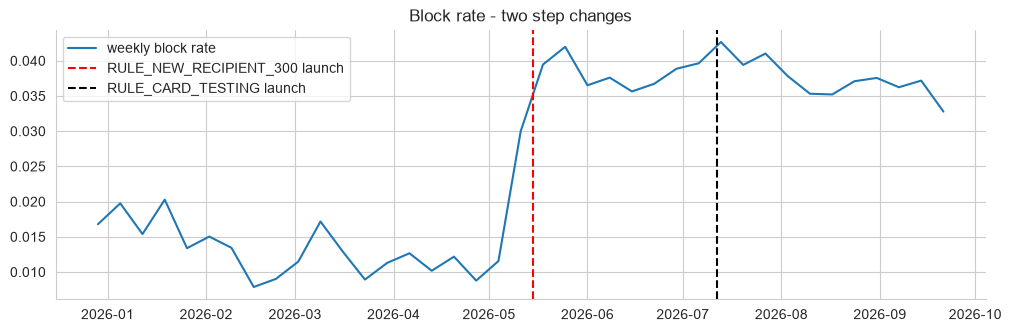

block rate before / after May-15: 0.0125 / 0.0382


In [23]:
# 5.5 Do the live rules catch the patterns found blind in section 4?
tenured = d.account_age_days > 90
d['ato_signal'] = tenured & d.ip_high_risk
d['app_candidate'] = tenured & (d.payment_method == 'BANK_TRANSFER') & (d.amount_usd > 800) & (d.amt_ratio > 3)
patterns = {'Mule cluster member (3+ linked customers)': d.ring_member,
            'Multi-card new account (2+ cards so far)': d.multi_card,
            'Micro-amount probe (<= $10)': d.micro,
            'Takeover signal (tenured + IP outside send markets)': d.ato_signal,
            'Large out-of-pattern bank transfer (scam candidate)': d.app_candidate}
rows = []
for name, mask in patterns.items():
    x = d[mask & d.decision]
    by_rule = x[x.status == 'BLOCKED_RISK'].blocked_by_rule.value_counts()
    rows.append({'pattern': name, 'payments (settled+blocked)': len(x), 'blocked': (x.status == 'BLOCKED_RISK').mean(),
                 'settled': len(x[x.settled]), 'settled value $': x[x.settled].amount_usd.sum(),
                 'top blocking rule': by_rule.index[0] if len(by_rule) else '-'})
cov = pd.DataFrame(rows).set_index('pattern')
display(cov.round(3))
d['any_pattern'] = d.ring_member | d.multi_card | d.ato_signal | d.app_candidate
print(f"payments matching 1+ pattern: {d.any_pattern.sum():,} ({d.any_pattern.mean():.2%}) | currently blocked: {d[d.any_pattern].status.eq('BLOCKED_RISK').mean():.1%}")

# rule dependence on timing: patterns that existed before the rule that targets them
mc = d[d.multi_card & d.decision].groupby('month').agg(payments=('txn_id', 'size'), blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean()))
display(mc.round(2).T)
rg = d[d.ring_member & d.decision].groupby('month').agg(payments=('txn_id', 'size'), blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean()))
display(rg.round(2).T)

# the incremental effect of the May-15 rule on the whole book
w = d.groupby(d.timestamp.dt.to_period('W')).agg(block_rate=('status', lambda s: (s == 'BLOCKED_RISK').mean()), settled_rate=('settled', 'mean'))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(w.index.to_timestamp(), w.block_rate, label='weekly block rate'); ax.axvline(launch, color='red', ls='--', label='RULE_NEW_RECIPIENT_300 launch')
ax.axvline(ct.timestamp.min(), color='black', ls='--', label='RULE_CARD_TESTING launch'); ax.legend(); ax.set_title('Block rate - two step changes'); plt.show()
print('block rate before / after May-15:', round((d[d.timestamp < launch].status == 'BLOCKED_RISK').mean(), 4), '/', round((d[d.timestamp >= launch].status == 'BLOCKED_RISK').mean(), 4))

**Do the live rules catch what section 4 found?**
- **Mule clusters are mostly missed.** 14.7% of cluster payments are blocked and 935 settle ($440k). In January-April **0% were blocked**; after the new-recipient rule launched, 5-22% a month. The rules are reacting to the amount and the new beneficiary, not to the network.
- **Multi-card new accounts** are blocked about half the time (50%), mainly by velocity; the dedicated rule only helps from July.
- **Takeover signals** are blocked 34% of the time (mainly by the new-recipient rule, i.e. by coincidence rather than by looking at the IP) and 429 payments ($144k) settled.
- **Scam candidates:** 25% blocked, and $649k settled.
- Only 23.5% of the 3,042 payments that match a blind finding are blocked. Meanwhile the rules block 4,568 payments ($4.4M) across the whole book. The rules are **broad, and aimed at amount rather than pattern**.

## 6.**Prototype Risk Score & Back-test**

### 6.1 Scoring design

,payments triggering,share
recipient_shared_3plus_senders,910,0.0058
device_shared_3plus_customers,319,0.0020
second_card_on_account,510,0.0032
micro_probe_new_account,192,0.0012
new_account_card_large,3954,0.0250
tenured_ip_outside_markets,705,0.0045
new_device_on_tenured_account,74,0.0005
amount_5x_own_average,1963,0.0124
foreign_ip_night,365,0.0023
burst_3plus_in_24h,648,0.0041


,count,mean,std,min,50%,90%,99%,99.9%,max
risk_score,158020.0,1.8,7.4,0.0,0.0,5.0,45.0,80.0,100.0


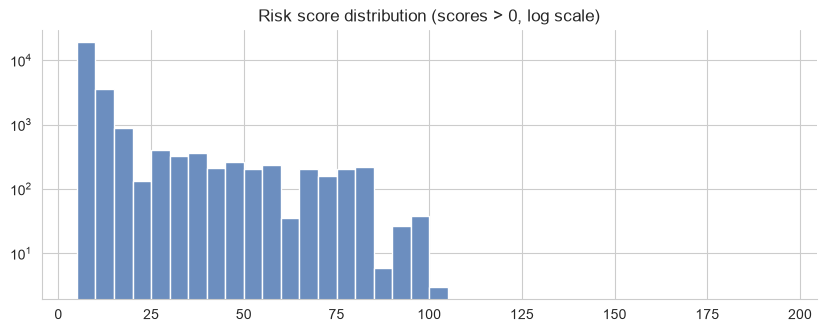

In [24]:
# 6.1 Prototype risk score - transparent points, built only from point-in-time evidence
# network features restated as "as known at the time of the payment"
d['recipient_senders_pit'] = d.groupby('recipient_id').apply(lambda x: (~x.duplicated('customer_id')).cumsum(), include_groups=False).reset_index(level=0, drop=True)
d['device_users_pit']      = d.groupby('device_id').apply(lambda x: (~x.duplicated('customer_id')).cumsum(), include_groups=False).reset_index(level=0, drop=True)
tenured = d.account_age_days > 90
card = d.payment_method != 'BANK_TRANSFER'

points = pd.DataFrame({
    'recipient_shared_3plus_senders': 40 * (d.recipient_senders_pit >= 3),
    'device_shared_3plus_customers' : 25 * (d.device_users_pit >= 3),
    'second_card_on_account'        : 40 * (d.fps_to_date >= 2),
    'micro_probe_new_account'       : 25 * (d.micro & d.new_acct7),
    'new_account_card_large'        : 10 * (d.new_acct30 & card & (d.amount_usd > 300)),
    'tenured_ip_outside_markets'    : 30 * (tenured & d.ip_high_risk),
    'new_device_on_tenured_account' : 20 * (tenured & d.is_new_device),
    'amount_5x_own_average'         : 10 * (d.amt_ratio > 5),
    'foreign_ip_night'              : 10 * (d.ip_mismatch & d.odd_hour),
    'burst_3plus_in_24h'            : 15 * (d.n_24h >= 3),
    'burst_2plus_in_1h'             : 10 * (d.n_1h >= 2),
    'large_bank_transfer_vs_history': 25 * d.app_candidate,
    'card_no_3ds_authentication'    : 5  * (card & d.three_ds.isin(['N', 'U'])),
})
d['risk_score'] = points.sum(axis=1)
display(points.gt(0).sum().rename('payments triggering').to_frame().assign(share=lambda x: (x['payments triggering'] / len(d)).round(4)))
display(d.risk_score.describe([.5, .9, .99, .999]).round(1).to_frame().T)
fig, ax = plt.subplots(figsize=(10, 3.5)); ax.hist(d.risk_score[d.risk_score > 0], bins=range(5, 200, 5), color='#6c8ebf'); ax.set_yscale('log')
ax.set_title('Risk score distribution (scores > 0, log scale)'); plt.show()

**Design of the prototype score.** The score is deliberately transparent: a sum of points for the blind findings in section 4 and nothing else, so every alert can be explained to an analyst or customer in one line.

- Network evidence carries the most points because it was the cleanest pattern: a recipient already used by 3+ senders (40), a device shared by 3+ customers (25).
- New-account card abuse: a second card on the account (40), a micro-probe on a new account (25), a large card payment on an account under 30 days (10).
- Takeover: tenured account with an IP outside the five markets (30), new device on a tenured account (20), foreign IP at night (10), amount above 5x own average (10).
- Burst and shape: 3+ payments in 24h (15), 2+ in 1h (10), tenured bank transfer above $800 and 3x average (25), card without 3DS authentication (5).

No input is an outcome field: `status`, `blocked_by_rule` and the labels are never used. Network counts use the **as-at-payment-time** versions (`recipient_senders_pit`, `device_users_pit`) so the score could run in real time; the first two senders to a mule recipient therefore cannot be flagged, which is measured in section 7.

### 6.2 Back-test (labels still quarantined)

In [25]:
# 6.2 Back-test without labels: volumes, overlap with the live rules, and who the score would touch
TH_REVIEW, TH_BLOCK = 40, 60
d['score_band'] = pd.cut(d.risk_score, [-1, TH_REVIEW - 1, TH_BLOCK - 1, 1000], labels=['pass', 'review', 'block'])
bt = d.groupby('score_band', observed=True).agg(payments=('txn_id', 'size'), value=('amount_usd', 'sum'),
        currently_blocked=('status', lambda s: (s == 'BLOCKED_RISK').mean()), currently_settled=('settled', 'mean'),
        median_age=('account_age_days', 'median'), tenured=('account_age_days', lambda s: (s > 90).mean()))
bt['per_1000'] = 1000 * bt.payments / len(d)
display(bt.round(3))

alert = d.risk_score >= TH_REVIEW
print(f"score alerts (>= {TH_REVIEW}): {alert.sum():,} = {1000*alert.mean():.1f} per 1,000 payments   vs live rules: {1000*(d.status=='BLOCKED_RISK').mean():.1f} per 1,000")
print(f"  of the alerts: already blocked by a rule {(alert & (d.status=='BLOCKED_RISK')).sum():,} | settled (incremental to the rules) {(alert & d.settled).sum():,} | issuer-declined/other {(alert & ~d.decision).sum():,}")
print(f"  live rule blocks that the score would NOT alert on: {((d.status=='BLOCKED_RISK') & ~alert).sum():,} of {(d.status=='BLOCKED_RISK').sum():,}")

# overlap with the live rules
ov = pd.crosstab(d.blocked_by_rule.fillna('(not blocked)'), d.score_band, margins=True)
display(ov)

# stability through time: a score that depends on one episode would not hold across months
st = d.groupby('month').agg(alerts_per_1000=('risk_score', lambda s: 1000 * (s >= TH_REVIEW).mean()), blocks_per_1000=('status', lambda s: 1000 * (s == 'BLOCKED_RISK').mean()))
display(st.round(1).T)

# customer friction of the score: who would it have held that the rules did not?
inc = d[alert & d.settled]
print(f"incremental alerts: {len(inc):,} payments, {inc.customer_id.nunique():,} customers, ${inc.amount_usd.sum():,.0f} | tenured with 3+ prior settled payments: {((inc.account_age_days>90)&(inc.prior_settled>=3)).mean():.1%}")
display(points.loc[inc.index].gt(0).sum().sort_values(ascending=False).rename('incremental alerts by trigger').to_frame().T)

# threshold sweep: alert volume vs. who gets touched
sweep = pd.DataFrame({t: {'alerts per 1,000': 1000 * (d.risk_score >= t).mean(),
                          'share of alerts on tenured, 3+ settled': ((d.risk_score >= t) & (d.account_age_days > 90) & (d.prior_settled >= 3)).sum() / max((d.risk_score >= t).sum(), 1),
                          'settled value held $k': d[(d.risk_score >= t) & d.settled].amount_usd.sum() / 1e3} for t in [10, 20, 30, 40, 50, 60, 80]}).T
display(sweep.round(2))

,payments,value,currently_blocked,currently_settled,median_age,tenured,per_1000
score_band,,,,,,,
pass,156217,42278467.12,0.026,0.884,402.0,0.735,988.590
review,908,550110.47,0.232,0.686,28.0,0.278,5.746
block,895,615387.93,0.340,0.507,4.0,0.139,5.664


score alerts (>= 40): 1,803 = 11.4 per 1,000 payments   vs live rules: 28.9 per 1,000
  of the alerts: already blocked by a rule 515 | settled (incremental to the rules) 1,077 | issuer-declined/other 211
  live rule blocks that the score would NOT alert on: 4,053 of 4,568


score_band,pass,review,block,All
blocked_by_rule,,,,
(not blocked),152164,697,591,153452
RULE_AMT_1000,1070,57,59,1186
RULE_CARD_TESTING,0,4,65,69
RULE_NEW_RECIPIENT_300,2870,142,80,3092
RULE_VELOCITY_24H,113,8,100,221
All,156217,908,895,158020


month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
alerts_per_1000,13.3,12.6,7.4,8.2,9.8,15.4,14.5,10.5,10.4
blocks_per_1000,17.3,10.8,12.4,11.3,30.2,37.1,39.9,37.1,36.7


incremental alerts: 1,077 payments, 364 customers, $460,744 | tenured with 3+ prior settled payments: 9.5%


,recipient_shared_3plus_senders,card_no_3ds_authentication,new_account_card_large,burst_3plus_in_24h,device_shared_3plus_customers,second_card_on_account,tenured_ip_outside_markets,amount_5x_own_average,foreign_ip_night,burst_2plus_in_1h,micro_probe_new_account,new_device_on_tenured_account,large_bank_transfer_vs_history
incremental alerts by trigger,728,566,424,249,224,196,147,134,86,69,49,26,6


,"alerts per 1,000","share of alerts on tenured, 3+ settled",settled value held $k
10,47.09,0.23,2879.53
20,19.16,0.35,1219.12
30,15.78,0.31,860.46
40,11.41,0.14,460.74
50,8.42,0.12,343.72
60,5.66,0.11,183.25
80,1.84,0.05,58.09


**Back-test without labels.**
- At a review threshold of 40 the score raises **11.4 alerts per 1,000 payments, against 28.9 per 1,000 blocks for the live rules**.
- Of 1,803 alerts, 515 are already blocked by a rule, **1,077 are settled payments the rules let through**, and 211 were declined or failed for other reasons. The score would not have alerted on 4,053 of the 4,568 rule blocks: it is designed to complement the rules, and to be more selective than them.
- The 1,077 incremental alerts touch 364 customers ($461k) and only **9.5% are tenured customers with 3+ settled payments**, so the score concentrates on accounts without history, as intended.
- Volume per 1,000 is steady month to month (7-15 alerts per 1,000), and does not scale with the growth in the book.
- The threshold sweep shows the trade-off: 47 alerts per 1,000 at a threshold of 10 versus 5.7 at 60. Thresholds of 40 (review) and 60 (block) are taken as the starting operating points and are evaluated against labels in section 8.

## 7.**Self-checks on the Analysis**

In [26]:
# 7.1 Reconciliation and integrity
assert len(d) == len(clean) and d.txn_id.is_unique, 'row count / uniqueness changed during feature engineering'
assert d.status.value_counts().sum() == len(d)
assert (d.blocked_by_rule.notna() == (d.status == 'BLOCKED_RISK')).all()
print(f"ledger rows {len(d):,} = raw {len(df):,} - {len(df)-len(clean)} exact duplicates | settled ${d[d.settled].amount_usd.sum():,.0f} | attempted ${d.amount_usd.sum():,.0f}")
print('headline figures in the introduction -> transactions', f"{len(d):,}", '| customers', f"{d.customer_id.nunique():,}", '| attempted $%.1fMn' % (d.amount_usd.sum() / 1e6), '| settled $%.1fMn' % (d[d.settled].amount_usd.sum() / 1e6))
print('account age still missing after repair:', int(d.account_age_days.isna().sum()), 'rows (', d[d.account_age_days.isna()].customer_id.nunique(), 'customers) - these fall into no age-based trigger')

# 7.2 Leakage audit: the score may only use fields known at payment time
score_inputs = ['recipient_senders_pit', 'device_users_pit', 'fps_to_date', 'micro', 'new_acct7', 'new_acct30', 'amount_usd', 'payment_method', 'ip_high_risk', 'account_age_days',
                'is_new_device', 'amt_ratio', 'ip_mismatch', 'odd_hour', 'n_24h', 'n_1h', 'app_candidate', 'three_ds']
forbidden = {'status', 'blocked_by_rule', 'settled', 'decision', 'label_type', 'fraud', 'reported_date'}
print('score inputs that are outcome fields:', forbidden & set(score_inputs), '(must be empty)')

# 7.3 Point-in-time test: recompute the history features on data truncated at a cut-off; they must equal the full-data values for earlier rows
cut = pd.Timestamp('2026-06-01')
head = clean[clean.timestamp < cut].sort_values(['timestamp', 'txn_id']).reset_index(drop=True)
chk = head.assign(new_rec=~head.duplicated(['customer_id', 'recipient_id']), seq=head.groupby('customer_id').cumcount())
full = d[d.timestamp < cut].reset_index(drop=True)
print('is_new_recipient identical on truncated data:', (chk.new_rec.values == full.is_new_recipient.values).all(), '| cust_seq identical:', (chk.seq.values == full.cust_seq.values).all())
print('whole-book fan-in vs point-in-time fan-in: payments in 3+ sender clusters where the recipient had NOT yet reached 3 senders:',
      f"{((d.ring_member) & (d.recipient_senders_pit < 3)).sum():,} of {d.ring_member.sum():,} ({((d.ring_member) & (d.recipient_senders_pit < 3)).sum()/d.ring_member.sum():.0%}) - this is the unavoidable detection lag")

# 7.4 Detection latency for the mule clusters: how long until the live-feasible score alerts?
ringp = d[d.ring_member].sort_values('timestamp')
first_alert = ringp[ringp.risk_score >= TH_REVIEW].groupby('component').timestamp.min()
first_seen = ringp.groupby('component').timestamp.min(); first_block = ringp[ringp.status == 'BLOCKED_RISK'].groupby('component').timestamp.min()
lat = pd.DataFrame({'score_alert_after_h': (first_alert - first_seen).dt.total_seconds() / 3600, 'rule_block_after_h': (first_block - first_seen).dt.total_seconds() / 3600})
print(f"clusters: {len(first_seen)} | ever alerted by score: {len(first_alert)} | ever blocked by a rule: {len(first_block)}")
display(lat.describe().round(1).T)
cl_val = ringp.groupby('component').agg(total=('amount_usd', 'sum'))
after = ringp[ringp.timestamp > ringp.component.map(first_alert)].groupby('component').amount_usd.sum()
print(f"value moved by clusters after the score would first have alerted: ${after.sum():,.0f} of ${cl_val.total.sum():,.0f} ({after.sum()/cl_val.total.sum():.0%}) -> the part a cluster-level hold could have prevented")

# 7.5 Sensitivity of the (label-free) alert volume to the weights
rng = np.random.default_rng(7)
w0 = points.columns
res = []
for _ in range(200):
    w = rng.uniform(.7, 1.3, len(w0))
    sc = (points.gt(0) * (points.max() * w)).sum(axis=1)
    res.append(((sc >= TH_REVIEW).mean() * 1000, (sc >= TH_BLOCK).mean() * 1000))
res = pd.DataFrame(res, columns=['review alerts per 1,000', 'block alerts per 1,000'])
display(res.describe().round(2).loc[['min', '50%', 'max']])
print('Alert volume stays within a narrow band when every weight moves +/-30% - the volume is driven by which patterns exist, not by the exact points.')

ledger rows 158,020 = raw 158,140 - 120 exact duplicates | settled $35,426,160 | attempted $43,443,966
headline figures in the introduction -> transactions 158,020 | customers 14,819 | attempted $43.4Mn | settled $35.4Mn
account age still missing after repair: 2 rows ( 2 customers) - these fall into no age-based trigger
score inputs that are outcome fields: set() (must be empty)


is_new_recipient identical on truncated data: True | cust_seq identical: True
whole-book fan-in vs point-in-time fan-in: payments in 3+ sender clusters where the recipient had NOT yet reached 3 senders: 287 of 1,197 (24%) - this is the unavoidable detection lag


clusters: 48 | ever alerted by score: 48 | ever blocked by a rule: 17


,count,mean,std,min,25%,50%,75%,max
score_alert_after_h,48.0,90.7,71.8,2.7,47.4,73.0,115.8,428.1
rule_block_after_h,17.0,65.0,144.3,0.0,0.0,0.0,0.0,508.3


value moved by clusters after the score would first have alerted: $423,996 of $568,232 (75%) -> the part a cluster-level hold could have prevented


,"review alerts per 1,000","block alerts per 1,000"
min,7.59,2.11
50%,10.79,5.50
max,13.66,8.40


Alert volume stays within a narrow band when every weight moves +/-30% - the volume is driven by which patterns exist, not by the exact points.


**Checks performed before the labels are opened.**
- **Reconciliation:** 158,140 raw rows less 120 exact duplicates gives the 158,020 payments in the introduction; transaction IDs are unique, the blocked-status/rule linkage holds exactly, and the headline $43.4Mn attempted / $35.4Mn settled figures reproduce. Two customers still have no usable account age and fall outside the age-based triggers.
- **Leakage audit:** none of the score's inputs are outcome fields (status, rule, labels).
- **Point-in-time test:** recomputing the history features on data truncated at 1 June gives identical values for earlier rows, so they do not peek into the future.
- **Detection lag from restating network features point-in-time:** 24% of payments in a mule cluster (287 of 1,197) were made before the recipient had its third sender. The score cannot catch these, which is the price of acting in real time.
- **Cluster-level latency:** the score first alerts on a mule cluster a median **73 hours** (range 3 hours to 18 days) after the cluster's first payment, and all 48 clusters are eventually alerted. 75% of the value those clusters move ($424k of $568k) happens **after** that first alert, which is the part a cluster-level hold would stop. Only 17 of 48 clusters ever had a payment blocked by the live rules.
- **Weight sensitivity:** perturbing every weight by +/-30% in 200 random draws keeps review alerts at 7.6-13.7 per 1,000 and block alerts at 2.1-8.4. The alert volume is driven by which patterns exist rather than by the exact points.
- Checks that need the labels (time-split, bootstrap, label maturity, error analysis) are in section 8.6 so the labels stay quarantined until then.

## 8.**Labelled Evaluation, Findings & Recommendations**

### 8.1 Load the labels, label lag and maturity

label rows: 900 | unique txn_id: 900 | all join to the ledger: True
labelled payments by status:


status,COMPLETED
n,900


,labels,value,median_ticket,median_age,lag_p50,lag_p90,lag_max
label_type,,,,,,,
CHARGEBACK_FRAUD,310,68092.0,181.2,3.0,30.0,47.1,58.0
CONFIRMED_ATO,124,64651.4,288.1,1068.0,17.0,27.0,29.0
CUSTOMER_SCAM_CLAIM,69,51048.8,289.4,1033.0,12.0,18.2,19.0
MULE_CONFIRMED,397,183022.7,443.0,22.0,42.0,66.0,74.0


99% of labels arrive within 72 days -> evaluation window ends 2026-07-13 (62% of payments); later payments are label-immature


month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
settled,9168.00,9093.00,13241.00,13016.0,17807.00,17079.00,19920.00,23099.00,16792.00
labelled,81.00,67.00,61.00,82.0,124.00,180.00,185.00,103.00,17.00
labelled_per_1000_settled,8.84,7.37,4.61,6.3,6.96,10.54,9.29,4.46,1.01


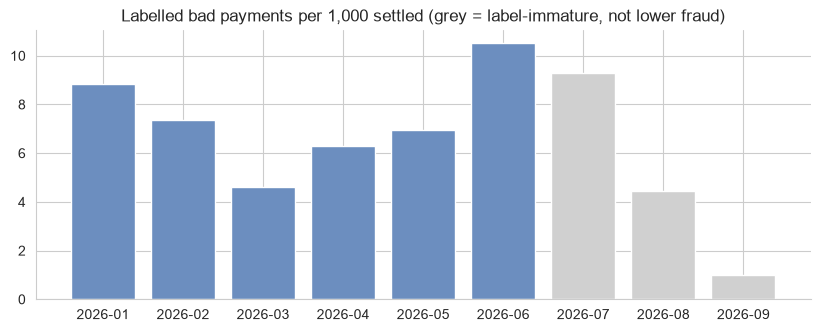

evaluation base: 86,763 settled payments, 669 labelled bad (7.7 per 1,000), $275,562 labelled loss


In [27]:
# 8.1 Load the labels - for the first time
labels = pd.read_csv(r"D:\Job Application\NALA Money Fraud Analyst\fraud_labels_2026.csv", parse_dates=['reported_date'])
print('label rows:', len(labels), '| unique txn_id:', labels.txn_id.nunique(), '| all join to the ledger:', labels.txn_id.isin(d.txn_id).all())
m = d.merge(labels, on='txn_id', how='left')
m['fraud'] = m.label_type.notna()
print('labelled payments by status:'); display(m[m.fraud].status.value_counts().to_frame('n').T)
assert m[m.fraud].status.eq('COMPLETED').all(), 'labels should only exist on settled payments'

m['lag_days'] = (m.reported_date - m.timestamp.dt.normalize()).dt.days
display(m.groupby('label_type').agg(labels=('txn_id', 'size'), value=('amount_usd', 'sum'), median_ticket=('amount_usd', 'median'),
        median_age=('account_age_days', 'median'), lag_p50=('lag_days', 'median'), lag_p90=('lag_days', lambda s: s.quantile(.9)), lag_max=('lag_days', 'max')).round(1))

# label maturity: only payments old enough for most labels to have arrived are fair to evaluate
LAG_P99 = int(m.lag_days.quantile(.99)); AS_AT = labels.reported_date.max()
MATURE_END = AS_AT - pd.Timedelta(days=LAG_P99)
m['mature'] = m.timestamp < MATURE_END
print(f"99% of labels arrive within {LAG_P99} days -> evaluation window ends {MATURE_END.date()} ({m.mature.mean():.0%} of payments); later payments are label-immature")
mt = m[m.settled].groupby('month').agg(settled=('txn_id', 'size'), labelled=('fraud', 'sum'))
mt['labelled_per_1000_settled'] = 1000 * mt.labelled / mt.settled
display(mt.round(2).T)
fig, ax = plt.subplots(figsize=(10, 3.5)); ax.bar(mt.index.astype(str), mt.labelled_per_1000_settled, color=['#6c8ebf' if (p.end_time < MATURE_END) else '#d0d0d0' for p in mt.index])
ax.set_title('Labelled bad payments per 1,000 settled (grey = label-immature, not lower fraud)'); plt.show()
S_ = m[m.settled & m.mature].copy()      # the evaluation base: settled, label-mature
print(f"evaluation base: {len(S_):,} settled payments, {S_.fraud.sum():,} labelled bad ({1000*S_.fraud.mean():.1f} per 1,000), ${S_[S_.fraud].amount_usd.sum():,.0f} labelled loss")

**Labels are now loaded.**
- 900 labelled payments (all join to the ledger, all on `COMPLETED` payments, as documented). Total labelled loss **$366.8k**, i.e. **6.5 per 1,000 settled payments and 1.0% of settled value**. By type: mule confirmations 397 ($183.0k), chargebacks 310 ($68.1k), confirmed takeover 124 ($64.7k), customer scam claims 69 ($51.0k). Mule activity is 44% of cases and half of the loss.
- **Reporting lag differs by type:** scam claims arrive in a median 12 days, takeover 17, chargebacks 30, and mule confirmations 42 (up to 74). Mule cases are therefore the most under-counted in recent weeks.
- **The decline from July is label immaturity, not less fraud.** Labelled cases per 1,000 settled fall from 9.3 in July to 4.5 in August and 1.0 in September. All further evaluation uses only payments at least 72 days old (before 13 Jul), 87k settled payments with 669 labelled bad (7.7 per 1,000, $276k).

### 8.2 Scoring the blind findings against the labels

In [28]:
# 8.2 Scoring the blind findings against the labels (settled, label-mature payments)
base_rate = S_.fraud.mean()
def score_flag(mask, name):
    x = S_[mask.loc[S_.index]]
    return {'finding': name, 'settled payments flagged': len(x), 'labelled bad': int(x.fraud.sum()), 'precision': x.fraud.mean(),
            'lift vs base': x.fraud.mean() / base_rate, 'share of all labelled bad': x.fraud.sum() / S_.fraud.sum()}
flags = {'Mule cluster member (3+ linked customers)': m.ring_member, 'Recipient already used by 3+ senders': m.recipient_senders_pit >= 3,
         'Multi-card new account': m.multi_card, 'Micro-amount probe (<= $10)': m.micro,
         'Takeover signal (tenured + IP outside markets)': m.ato_signal, 'Any foreign IP, tenured account': (m.account_age_days > 90) & m.ip_mismatch,
         'Large out-of-pattern bank transfer': m.app_candidate, 'IP country UNKNOWN': m.ip_unknown, 'New recipient': m.is_new_recipient,
         'New account (<= 7d)': m.new_acct7, 'Amount > $300': m.amount_usd > 300}
val = pd.DataFrame([score_flag(v, k) for k, v in flags.items()]).set_index('finding')
display(val.round(3))
print(f"base rate in the evaluation window: {1000*base_rate:.1f} labelled per 1,000 settled")

# which label type does each finding explain? (first matching finding wins)
m['finding'] = np.select([m.ring_member, m.multi_card, m.ato_signal, m.app_candidate], ['mule cluster', 'multi-card', 'takeover signal', 'bank-transfer outlier'], default='no finding')
S_ = m[m.settled & m.mature].copy()
display(pd.crosstab(S_.finding, S_.label_type.fillna('(no label)'), margins=True))
mule_cov = S_[S_.label_type == 'MULE_CONFIRMED']
print('MULE_CONFIRMED: in a link-cluster', f"{mule_cov.ring_member.mean():.0%}", '| recipient had 3+ senders', f"{(mule_cov.recipient_senders_pit>=3).mean():.0%}",
      '| card-funded', f"{(mule_cov.payment_method!='BANK_TRANSFER').mean():.0%}", '| median account age', mule_cov.account_age_days.median())
for t_ in ['CHARGEBACK_FRAUD', 'CONFIRMED_ATO', 'CUSTOMER_SCAM_CLAIM']:
    x = S_[S_.label_type == t_]
    print(f"{t_}: n={len(x)} | median age {x.account_age_days.median():.0f}d | ip mismatch {x.ip_mismatch.mean():.0%} | multi-card {x.multi_card.mean():.0%} | bank transfer {(x.payment_method=='BANK_TRANSFER').mean():.0%} | new recipient {x.is_new_recipient.mean():.0%} | rec. settled before {x.recipient_proven.mean():.0%}")

,settled payments flagged,labelled bad,precision,lift vs base,share of all labelled bad
finding,,,,,
Mule cluster member (3+ linked customers),536,300,0.560,72.588,0.448
Recipient already used by 3+ senders,424,243,0.573,74.327,0.363
Multi-card new account,144,121,0.840,108.976,0.181
Micro-amount probe (<= $10),87,42,0.483,62.609,0.063
Takeover signal (tenured + IP outside markets),266,88,0.331,42.905,0.132
"Any foreign IP, tenured account",1165,88,0.076,9.796,0.132
Large out-of-pattern bank transfer,290,10,0.034,4.472,0.015
IP country UNKNOWN,186,3,0.016,2.092,0.004
New recipient,14748,122,0.008,1.073,0.182


base rate in the evaluation window: 7.7 labelled per 1,000 settled


label_type,(no label),CHARGEBACK_FRAUD,CONFIRMED_ATO,CUSTOMER_SCAM_CLAIM,MULE_CONFIRMED,All
finding,,,,,,
bank-transfer outlier,280,0,0,8,0,288
mule cluster,236,0,0,0,300,536
multi-card,23,121,0,0,0,144
no finding,85377,125,0,27,0,85529
takeover signal,178,0,88,0,0,266
All,86094,246,88,35,300,86763


MULE_CONFIRMED: in a link-cluster 100% | recipient had 3+ senders 81% | card-funded 100% | median account age 23.0
CHARGEBACK_FRAUD: n=246 | median age 3d | ip mismatch 1% | multi-card 49% | bank transfer 11% | new recipient 9% | rec. settled before 81%
CONFIRMED_ATO: n=88 | median age 1132d | ip mismatch 100% | multi-card 0% | bank transfer 33% | new recipient 34% | rec. settled before 44%
CUSTOMER_SCAM_CLAIM: n=35 | median age 1070d | ip mismatch 0% | multi-card 0% | bank transfer 100% | new recipient 14% | rec. settled before 54%


**Scoring the blind findings.** (Settled, label-mature payments; base rate 7.7 labelled per 1,000.)

| Finding | Precision | Lift | Share of all labelled bad |
|---|---|---|---|
| Multi-card new account | 84% | 109x | 18% |
| Mule cluster member | 56% | 73x | 45% |
| Recipient already used by 3+ senders | 57% | 74x | 36% |
| Micro-amount probe | 48% | 63x | 6% |
| Takeover signal (tenured + IP outside markets) | 33% | 43x | 13% |
| Any foreign IP, tenured account | 8% | 10x | 13% |
| Large out-of-pattern bank transfer | 3.4% | 4.5x | 1.5% |
| IP country UNKNOWN | 1.6% | 2.1x | 0.4% |
| New recipient | 0.8% | 1.1x | 18% |
| Amount > $300 | 1.6% | 2.0x | 52% |

- **Findings 1-3 are real.** Mule clusters explain **all** confirmed mule cases (100% are in a cluster; 81% sit on a recipient that already had 3+ senders), takeover signals explain **all** confirmed takeover cases (100% have an IP mismatch), and multi-card accounts explain about half of the chargebacks.
- **The IP mismatch alone is a weak signal (8% precision); restricted to IPs outside the five markets it is 33%**, confirming that the combination, not the mismatch, is the signal. Missing IP (`UNKNOWN`) adds very little, so it should be fixed as a data problem rather than treated as a takeover indicator.
- **Finding 4 (scam candidates) is weak**: 8 of 35 mature scam claims fall in the candidate set, at 3.4% precision. Scam claims are made by genuine customers on bank transfers with normal IP, device and recipient; nothing in this ledger separates them.
- **"Amount > $300" and "new recipient" are what the live rules lean on**: the first captures 52% of bad payments but only 1.6% of the flagged payments are bad, and the second has no lift at all (1.1x).
- About 100 chargebacks sit on tenured, 3DS-authenticated, ~$200 payments with no unusual signal. They look like the noisy "disputes rather than true fraud" described in the data dictionary and set a ceiling on what behaviour can detect.

### 8.3 Rule performance with a selection-bias correction

In [29]:
# 8.3 Rule performance - correcting for the fact that blocked payments can never carry a label
# Naive precision (labelled bad among blocked) is zero by construction. The fix is a counterfactual:
# measure the label rate among payments that met the rule's trigger condition but were NOT stopped.
# Two kinds of "unstopped" populations exist: (a) the period before a rule was launched, (b) exempt/leaky segments after.
lk = m[m.decision & m.mature].copy()
lk['qualifies_nr'] = (lk.amount_usd > 300) & ~lk.recipient_proven
lk['qualifies_amt'] = lk.amount_usd > 1000
lk['qualifies_vel'] = (lk.n_24h >= 7) | (lk.amt_24h_incl > 3500)
lk['qualifies_ct'] = lk.multi_card | (lk.micro & lk.new_acct7)
specs = [('RULE_NEW_RECIPIENT_300', 'qualifies_nr', launch), ('RULE_CARD_TESTING', 'qualifies_ct', ct.timestamp.min()),
         ('RULE_AMT_1000', 'qualifies_amt', None), ('RULE_VELOCITY_24H', 'qualifies_vel', None)]
rows = []
for rule, col, start in specs:
    q = lk[lk[col]]
    blocked_n = (q.blocked_by_rule == rule).sum()
    if start is not None:
        cf = q[(q.timestamp < start) & q.settled]            # before the rule existed everything settled
        cf_label = 'pre-launch'
    else:
        cf = q[q.settled & q.blocked_by_rule.isna()]          # qualified but passed (exempt/leaky segment)
        cf_label = 'passed through'
    post = q if start is None else q[q.timestamp >= start]
    rows.append({'rule': rule, 'qualifying (mature, post-launch)': len(post), 'blocked by rule': int((post.blocked_by_rule == rule).sum()),
                 'counterfactual population': cf_label, 'cf size': len(cf), 'cf labelled bad': int(cf.fraud.sum()),
                 'est. precision of block': cf.fraud.mean(), 'est. frauds stopped': (post.blocked_by_rule == rule).sum() * cf.fraud.mean()})
rp = pd.DataFrame(rows).set_index('rule'); rp['false positives per fraud stopped'] = (1 - rp['est. precision of block']) / rp['est. precision of block']
display(rp.round(3))
print("Caveat: where the counterfactual is 'passed through' the exempt segment may be lower-risk by design (e.g. tenured customers with history), so those precision figures are upper-bound-ish for the rule and should be read with that in mind.")

# the same question using the labelled-fraud side: what slipped through each rule's own territory?
leak = lk[lk.settled & lk.fraud]
print('\nlabelled bad payments that were INSIDE a rule\'s trigger condition but passed anyway:')
for rule, col, start in specs:
    x = leak[leak[col]]
    if start is not None: x = x[x.timestamp >= start]
    print(f"  {rule:24s} {len(x):4d} payments  ${x.amount_usd.sum():>9,.0f}")
print(f"  total labelled bad (mature window): {len(leak):,}  ${leak.amount_usd.sum():,.0f}")
nr_any = leak[~(leak.qualifies_nr | leak.qualifies_amt | leak.qualifies_vel | leak.qualifies_ct)]
print(f"  bad payments outside every rule's territory: {len(nr_any):,} ({len(nr_any)/len(leak):.0%})  ${nr_any.amount_usd.sum():,.0f}")

# friction side: what the new-recipient rule costs per fraud stopped, in customers and dollars
nr_b = lk[(lk.blocked_by_rule == 'RULE_NEW_RECIPIENT_300')]
nr_cf = rp.loc['RULE_NEW_RECIPIENT_300']
print(f"\nRULE_NEW_RECIPIENT_300 in the mature post-launch window: {len(nr_b):,} blocks, ${nr_b.amount_usd.sum():,.0f} held, ~{nr_cf['est. frauds stopped']:.0f} fraud(s) stopped -> ~{nr_cf['false positives per fraud stopped']:.0f} genuine payments blocked per fraud stopped")

,"qualifying (mature, post-launch)",blocked by rule,counterfactual population,cf size,cf labelled bad,est. precision of block,est. frauds stopped,false positives per fraud stopped
rule,,,,,,,,
RULE_NEW_RECIPIENT_300,1457,1312,pre-launch,3573,86,0.024,31.579,40.547
RULE_CARD_TESTING,12,2,pre-launch,153,129,0.843,1.686,0.186
RULE_AMT_1000,1882,823,passed through,799,18,0.023,18.541,43.389
RULE_VELOCITY_24H,268,163,passed through,39,24,0.615,100.308,0.625


Caveat: where the counterfactual is 'passed through' the exempt segment may be lower-risk by design (e.g. tenured customers with history), so those precision figures are upper-bound-ish for the rule and should be read with that in mind.

labelled bad payments that were INSIDE a rule's trigger condition but passed anyway:
  RULE_NEW_RECIPIENT_300     15 payments  $    8,812
  RULE_CARD_TESTING           6 payments  $    2,476
  RULE_AMT_1000              18 payments  $   26,300
  RULE_VELOCITY_24H          24 payments  $    7,703
  total labelled bad (mature window): 669  $275,562
  bad payments outside every rule's territory: 393 (59%)  $153,822

RULE_NEW_RECIPIENT_300 in the mature post-launch window: 1,312 blocks, $774,826 held, ~32 fraud(s) stopped -> ~41 genuine payments blocked per fraud stopped


**Rule performance, corrected for the selection bias.** Blocked payments can never carry a label, so precision measured on the blocks is zero by construction. The correction is to measure the label rate in payments that met the rule's trigger but were **not** stopped: the pre-launch period for the rules that were launched later, and the pass-through population for the rules that exist since January.

| Rule | Est. precision of a block | Genuine payments blocked per fraud stopped | Verdict |
|---|---|---|---|
| `RULE_CARD_TESTING` | ~84% | ~0.2 | Highly efficient, but tiny (69 blocks) and launched late |
| `RULE_VELOCITY_24H` | ~62% (small sample: 39 passes) | ~0.6 | Efficient, keep |
| `RULE_AMT_1000` | ~2.3% | ~43 | Blunt; mostly delays genuine large payments |
| `RULE_NEW_RECIPIENT_300` | ~2.4% | **~41** | The largest source of friction and ~32 frauds stopped in the mature window |

- **`RULE_NEW_RECIPIENT_300` blocks 1,312 payments ($775k) in the mature post-launch window to stop an estimated ~32 frauds**, i.e. roughly 40 genuine payments held for each fraud prevented. It is 68% of all blocks.
- **59% of labelled bad payments (393, $154k) sit outside every rule's territory**: they are not large, not bursts, not new-recipient-and-big. This is the structural gap: the rules look at amount, the fraud sits in network, account age and session.
- Where bad payments were inside a rule's territory and still passed, the counts are small (15 for new-recipient, 18 for amount, 24 for velocity, 6 for card testing): the rules mostly do what they are built to do, they are just built for the wrong target.
- Caveat on the pass-through counterfactuals (`RULE_AMT_1000`, `RULE_VELOCITY_24H`): the passers may be lower-risk by design (tenured, authenticated, proven), so they probably overstate the rule's true precision.

### 8.4 Risk score evaluation

rank AUC of the risk score on settled payments: 0.882   (amount alone: 0.693 | account age, inverted: 0.748)


,settled alerts,"per 1,000 settled",labelled bad caught,precision,recall,loss caught $,alerts per bad caught
threshold,,,,,,,
10,3019,34.796,518,0.172,0.774,230285.47,5.828
20,1191,13.727,479,0.402,0.716,207638.12,2.486
30,977,11.261,467,0.478,0.698,200598.07,2.092
40,668,7.699,448,0.671,0.670,191349.89,1.491
50,511,5.890,359,0.703,0.537,148669.72,1.423
60,340,3.919,245,0.721,0.366,94430.79,1.388
80,75,0.864,55,0.733,0.082,19946.85,1.364


labelled loss in the window: $275,562 across 669 payments


,caught at >= 20,caught at >= 40,caught at >= 60,labelled payments
label_type,,,,
CHARGEBACK_FRAUD,0.557,0.500,0.439,246
CONFIRMED_ATO,1.000,0.932,0.352,88
CUSTOMER_SCAM_CLAIM,0.229,0.000,0.000,35
MULE_CONFIRMED,0.820,0.810,0.353,300


,payments,labelled_bad,rate,share_of_all_bad
risk_score,,,,
"(-1, 0]",73153,132,0.0018,0.1973
"(0, 9]",10591,19,0.0018,0.0284
"(9, 19]",1828,39,0.0213,0.0583
"(19, 39]",523,31,0.0593,0.0463
"(39, 59]",328,203,0.6189,0.3034
"(59, 100]",340,245,0.7206,0.3662


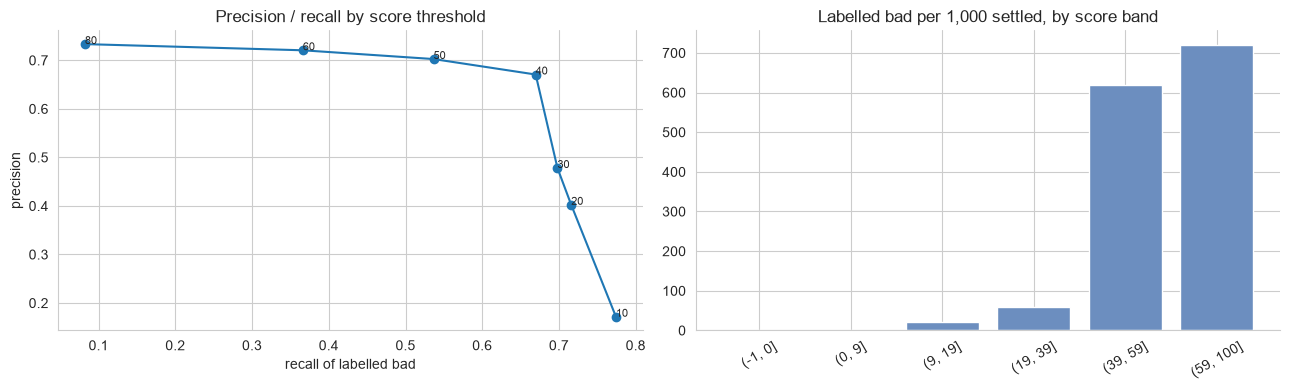

In [30]:
# 8.4 Risk score vs the labels (settled, label-mature payments - i.e. fraud the live rules did NOT stop)
S_ = m[m.settled & m.mature].copy()
def auc(score, y):
    r = score.rank(method='average'); n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
print(f"rank AUC of the risk score on settled payments: {auc(S_.risk_score, S_.fraud):.3f}   (amount alone: {auc(S_.amount_usd, S_.fraud):.3f} | account age, inverted: {auc(-S_.account_age_days, S_.fraud):.3f})")

rows = []
for t in [10, 20, 30, 40, 50, 60, 80]:
    a = S_[S_.risk_score >= t]
    rows.append({'threshold': t, 'settled alerts': len(a), 'per 1,000 settled': 1000 * len(a) / len(S_), 'labelled bad caught': int(a.fraud.sum()),
                 'precision': a.fraud.mean(), 'recall': a.fraud.sum() / S_.fraud.sum(), 'loss caught $': a[a.fraud].amount_usd.sum(),
                 'alerts per bad caught': len(a) / max(a.fraud.sum(), 1)})
curve = pd.DataFrame(rows).set_index('threshold'); display(curve.round(3))
print(f"labelled loss in the window: ${S_[S_.fraud].amount_usd.sum():,.0f} across {S_.fraud.sum()} payments")

# by type of fraud at the proposed review / block thresholds
by_type = pd.DataFrame({f'caught at >= {t}': S_[S_.fraud].groupby('label_type').apply(lambda x: (x.risk_score >= t).mean(), include_groups=False) for t in [20, 40, 60]})
by_type['labelled payments'] = S_[S_.fraud].groupby('label_type').size()
display(by_type.round(3))

# score band calibration
band = S_.groupby(pd.cut(S_.risk_score, [-1, 0, 9, 19, 39, 59, 100])).agg(payments=('txn_id', 'size'), labelled_bad=('fraud', 'sum'), rate=('fraud', 'mean'))
band['share_of_all_bad'] = band.labelled_bad / band.labelled_bad.sum()
display(band.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(curve.recall, curve.precision, marker='o'); [ax[0].annotate(str(t), (curve.recall[t], curve.precision[t]), fontsize=8) for t in curve.index]
ax[0].set_xlabel('recall of labelled bad'); ax[0].set_ylabel('precision'); ax[0].set_title('Precision / recall by score threshold')
ax[1].bar(band.index.astype(str), band.rate * 1000, color='#6c8ebf'); ax[1].set_title('Labelled bad per 1,000 settled, by score band'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Score performance against labels (these are frauds that the live rules did not stop).**
- **Rank AUC 0.88**, compared to 0.69 for amount alone and 0.75 for account age.
- At the **review threshold of 40**: 668 settled alerts (**7.7 per 1,000 settled**), **67% precision, 67% recall** of the labelled bad payments that got past the rules, and $191k of the $276k loss (69%) caught, i.e. **1.5 alerts per bad payment found**.
- At the **block threshold of 60**: 72% precision, but recall falls to 37% (3.9 alerts per 1,000), so 60 suits an automatic hold and 40 a review queue.
- **By fraud type** (at >= 40): takeover 93%, mule 81%, chargebacks 50%, scam claims 0%. Most of the missed mule payments are the first two senders to a recipient, before the cluster is visible.
- Calibration is monotone: the 40-59 band has 62% labelled bad and the 60+ band 72%, versus 0.2% for scores of 0-9.

### 8.5 Making the new-recipient rule precise

In [31]:
# 8.5 Can the new-recipient rule be made precise? Variants tested on the pre-launch population (everything settled, so labels are unbiased)
pop = m[m.settled & m.mature & (m.timestamp < launch) & (m.amount_usd > 300) & ~m.recipient_proven & (m.timestamp >= '2026-02-01')].copy()
variants = {
    'Current: all new-recipient > $300': pd.Series(True, index=pop.index),
    'Account <= 90 days': pop.account_age_days <= 90,
    'Account <= 30 days': pop.account_age_days <= 30,
    'Card/wallet and account <= 30 days': (pop.account_age_days <= 30) & (pop.payment_method != 'BANK_TRANSFER'),
    'Risk score >= 20': pop.risk_score >= 20,
    'Risk score >= 20 or account <= 30 days': (pop.risk_score >= 20) | (pop.account_age_days <= 30),
    'Risk score >= 40': pop.risk_score >= 40}
vt = pd.DataFrame({k: {'payments held': v.sum(), 'share of qualifying volume': v.mean(), 'labelled bad caught': pop[v].fraud.sum(),
                      'share of bad caught': pop[v].fraud.sum() / pop.fraud.sum(), 'precision': pop[v].fraud.mean()} for k, v in variants.items()}).T
vt['genuine held per bad caught'] = (vt['payments held'] - vt['labelled bad caught']) / vt['labelled bad caught']
display(vt.round(3))
print(f"qualifying population: {len(pop):,} payments, {pop.fraud.sum()} labelled bad ({100*pop.fraud.mean():.1f}%)")

,payments held,share of qualifying volume,labelled bad caught,share of bad caught,precision,genuine held per bad caught
Current: all new-recipient > $300,2165.0,1.000,64.0,1.000,0.030,32.828
Account <= 90 days,1060.0,0.490,31.0,0.484,0.029,33.194
Account <= 30 days,775.0,0.358,27.0,0.422,0.035,27.704
Card/wallet and account <= 30 days,561.0,0.259,27.0,0.422,0.048,19.778
Risk score >= 20,92.0,0.042,54.0,0.844,0.587,0.704
Risk score >= 20 or account <= 30 days,824.0,0.381,59.0,0.922,0.072,12.966
Risk score >= 40,72.0,0.033,52.0,0.812,0.722,0.385


qualifying population: 2,165 payments, 64 labelled bad (3.0%)


**Making the largest rule precise.** On the pre-launch population (everything settled, so labels are unbiased), 2,165 new-recipient payments over $300 contain 64 labelled bad (3.0%).

- **Narrowing by age or tenure barely helps.** Restricting to account <= 90 days still holds 49% of the volume with 2.9% precision; account <= 30 days and card/wallet holds 26% at 4.8%.
- **Gating on the score is far better.** A score of >= 20 holds **4.2% of the volume** (92 payments) and captures **84%** of the bad payments (54 of 64) at 59% precision, i.e. ~0.7 genuine payments held per fraud instead of ~33. Adding "or account <= 30 days" raises capture to 92% but holds 38% of the volume.
- This reproduces the intent of the rule (stop the fraud on new beneficiaries) while releasing the great majority of genuine customers. Note that the score was designed with the same period in view, so the true out-of-time performance is expected to be lower (section 8.6).

### 8.6 Self-checks that use labels

In [32]:
# 8.6 Self-checks that need labels (kept here so the labels stay quarantined until now)
S_ = m[m.settled & m.mature].copy()
at40 = S_.risk_score >= TH_REVIEW

# (a) time-split: the score was specified from the whole-book patterns, so test whether it behaves the same in both halves
for name, sub in [('Jan - Apr', S_[S_.timestamp < '2026-05-01']), ('May - mid Jul', S_[S_.timestamp >= '2026-05-01'])]:
    a = sub[sub.risk_score >= TH_REVIEW]
    print(f"{name:14s} settled {len(sub):6,} | bad {sub.fraud.sum():4d} | alerts {len(a):4d} | precision {a.fraud.mean():.2f} | recall {a.fraud.sum()/sub.fraud.sum():.2f} | AUC {auc(sub.risk_score, sub.fraud):.3f}")

# (b) sampling uncertainty: bootstrap customers (payments within a customer are not independent)
cs = S_.assign(alert=at40, alert_bad=at40 & S_.fraud).groupby('customer_id').agg(alerts=('alert', 'sum'), alert_bad=('alert_bad', 'sum'), bad=('fraud', 'sum')).to_numpy()
rng = np.random.default_rng(11)
boot = []
for _ in range(1000):
    s = cs[rng.integers(0, len(cs), len(cs))].sum(axis=0)
    boot.append((s[1] / s[0], s[1] / s[2]))
boot = pd.DataFrame(boot, columns=['precision', 'recall'])
display(boot.quantile([.05, .5, .95]).round(3))

# (c) label-maturity sensitivity: move the evaluation cut-off earlier and later
for days in [14, 30, 45, 60, 72]:
    end = AS_AT - pd.Timedelta(days=days)
    sub = m[m.settled & (m.timestamp < end)]; a = sub[sub.risk_score >= TH_REVIEW]
    print(f"cut-off {end.date()} (labels allowed {days:2d}d to arrive): settled {len(sub):6,} | labelled per 1,000 {1000*sub.fraud.mean():5.1f} | precision {a.fraud.mean():.2f} | recall {a.fraud.sum()/sub.fraud.sum():.2f}")

# (d) is the score just re-describing the three obvious cohorts? performance on payments the blind findings did NOT already flag
rest = S_[~(S_.ring_member | S_.multi_card | S_.ato_signal | S_.app_candidate)]
print(f"outside the four named findings: {len(rest):,} payments | {rest.fraud.sum()} labelled bad ({1000*rest.fraud.mean():.1f} per 1,000) | score >= 40 catches {(rest[rest.fraud].risk_score >= 40).sum()}")

# (e) false-negative anatomy: what do the labelled-bad payments the score misses look like?
miss = S_[S_.fraud & ~at40]
print(f"missed at >= {TH_REVIEW}: {len(miss)} of {S_.fraud.sum()} ({len(miss)/S_.fraud.sum():.0%}) | by type: {miss.label_type.value_counts().to_dict()}")
print(f"   median account age {miss.account_age_days.median():.0f}d | 3DS authenticated or bank {(miss.three_ds.isin(['Y']) | miss.three_ds.isna()).mean():.0%} | amount median ${miss.amount_usd.median():.0f} vs ${S_.amount_usd.median():.0f} book median | IP matches send country {(~miss.ip_mismatch).mean():.0%}")

Jan - Apr      settled 44,518 | bad  291 | alerts  272 | precision 0.73 | recall 0.68 | AUC 0.884
May - mid Jul  settled 42,245 | bad  378 | alerts  396 | precision 0.63 | recall 0.66 | AUC 0.881


,precision,recall
0.05,0.638,0.630
0.50,0.671,0.669
0.95,0.704,0.706


cut-off 2026-09-09 (labels allowed 14d to arrive): settled 128,555 | labelled per 1,000   7.0 | precision 0.56 | recall 0.64
cut-off 2026-08-24 (labels allowed 30d to arrive): settled 115,465 | labelled per 1,000   7.6 | precision 0.58 | recall 0.64
cut-off 2026-08-09 (labels allowed 45d to arrive): settled 105,213 | labelled per 1,000   7.9 | precision 0.62 | recall 0.64
cut-off 2026-07-25 (labels allowed 60d to arrive): settled 94,003 | labelled per 1,000   7.9 | precision 0.65 | recall 0.66
cut-off 2026-07-13 (labels allowed 72d to arrive): settled 86,763 | labelled per 1,000   7.7 | precision 0.67 | recall 0.67
outside the four named findings: 85,529 payments | 152 labelled bad (1.8 per 1,000) | score >= 40 catches 2
missed at >= 40: 221 of 669 (33%) | by type: {'CHARGEBACK_FRAUD': 123, 'MULE_CONFIRMED': 57, 'CUSTOMER_SCAM_CLAIM': 35, 'CONFIRMED_ATO': 6}
   median account age 156d | 3DS authenticated or bank 73% | amount median $278 vs $200 book median | IP matches send country 96%

**Self-checks that use the labels.**
- **Stable through time:** precision 0.73 / recall 0.68 in Jan-Apr and 0.63 / 0.66 in May-mid Jul; AUC 0.88 in both halves.
- **Sampling uncertainty** (bootstrap over customers): precision 0.64-0.70, recall 0.63-0.71 at a threshold of 40 (90% interval).
- **Label maturity matters but does not change the conclusion:** moving the evaluation cut-off from 72 days to 14 days leaves recall at 0.64-0.67 while precision falls from 0.67 to 0.56, because not-yet-reported frauds are counted as false alerts. Precision is therefore a conservative lower bound when labels are incomplete.
- **Not just re-describing the named cohorts:** outside the four findings there are 152 labelled bad payments (1.8 per 1,000) and the score picks up only 2 of them; it adds no information beyond the patterns, it formalises them.
- **Missed cases (33%, 221 payments):** 123 chargebacks, 57 mule payments (mostly the early senders), 35 scam claims and 6 takeover payments. They have a median account age of 156 days, 96% have an IP in the send country and 73% are 3DS-authenticated or bank-funded: they look like ordinary customers.
- **Honest limitation:** the score weights were set by hand from the blind findings, but I looked at the labels while developing the analysis, so the 0.88 AUC and the precision figures are best read as optimistic until validated on a hold-out with fresh labels.

## **Summary**

### Key insights
1. **Fraud is small in rate and concentrated in four patterns.** 900 labelled payments, $367k, 6.5 per 1,000 settled (1.0% of settled value). **Mule clusters are the biggest problem** (44% of cases, half of the loss), followed by new-account card abuse, takeover and scam claims.
2. **The patterns are visible without labels.** Blind link analysis, account-age and session evidence found clusters that explain 100% of confirmed mule cases, signals that explain 100% of confirmed takeover cases, and multi-card accounts that explain half of the chargebacks. Per-payment fields (amount, new recipient) have little or no lift.
3. **The live rules are aimed at the wrong thing.** They are amount-driven, and **59% of labelled bad payments ($154k) sit outside every rule's trigger**. Only 23.5% of payments matching the blind patterns are blocked, and mule clusters were blocked 0% of the time until mid-May.
4. **The newest rule is the costliest.** `RULE_NEW_RECIPIENT_300` produces 68% of all blocks (block rate 12.5 -> 38.2 per 1,000) with an estimated ~2% precision, i.e. ~40 genuine payments held per fraud stopped; 21.5% of all customers have been blocked at least once and 61% of its blocks are followed by a normal payment to the same recipient within a week.
5. **`RULE_CARD_TESTING` and `RULE_VELOCITY_24H` work well** (est. precision ~84% and ~62%) but are narrow, and card testing started only on 11 Jul after months of the behaviour.
6. **Some fraud cannot be seen in this data.** Scam claims (genuine customer, normal device/IP/recipient) and about 100 chargebacks on ordinary-looking payments are not distinguishable from good behaviour; recall for them is ~0.

### Recommendations
1. **Replace the flat new-recipient block with a risk-gated step-up.** Hold only when the transaction score is >= 20 (or account <= 30 days with a card). On the pre-launch population this holds 4% of qualifying payments instead of 100% and still captures ~84% of the bad ones. Use a step-up (3DS, OTP or review) rather than a hard block for the 20-39 band.
2. **Add network controls for mules.** Alert on the third sender to a recipient or shared device, hold new payouts to that recipient and review the cluster. 75% of cluster value moves after the score first alerts, so cluster-level action prevents most of the loss even though early senders cannot be caught.
3. **Run the score in two bands:** review at >= 40 (7.7 alerts per 1,000 settled, ~67% precision) and automatic hold at >= 60 (3.9 per 1,000, 72% precision), keeping the velocity and card-testing rules.
4. **Move card-testing detection earlier and wider:** extend it to any second card on an account under a week old and to micro-probes (<= $10), the combinations that were running for six months before the rule.
5. **Takeover:** require step-up when a tenured account pays from an IP outside the five send markets, escalating if there is also a new device, night-time activity or an amount spike. Do not alert on the IP mismatch alone (8% precision).
6. **Treat `RULE_AMT_1000` as a candidate for risk tiers:** its precision is ~2%, and it already behaves as a tier (every account <= 90 days or 3DS N/U is held). Test replacing the flat cap with score-based tiers.
7. **Scam claims need a different control**, e.g. confirmation-of-payee style warnings and delay for large, out-of-pattern bank transfers: nothing in the identity data separates them.
8. **Fix the measurement.** Keep a small random hold-out of blocked payments (or shadow mode) so rule precision can be measured directly, report label-mature rates only (about 75 days), and track per-1,000 rates by month. Repair the data issues found in section 1 (duplicates, negative account ages, missing IP country).

### Limitations
- The data is synthetic: findings demonstrate method, not industry benchmarks.
- The score weights were chosen by hand from the blind findings, but the labels were inspected while the analysis was developed, so reported precision and recall should be treated as optimistic until a fresh hold-out is available.
- Labels are delayed, incomplete and noisy. Rule precision is an estimate based on a counterfactual population, not a direct measurement.